# Laboratorio — Preparación de Datos 1

**Dataset:** `bank_full.csv`  
**Entorno:** Google Colab  
**Variable objetivo:** `y`

# 1. Carga y exploración inicial

## 1.1. Carga del dataset



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ruta = "/content/bank_full.csv"

# sep=None permite detectar automáticamente el separador del archivo.
df = pd.read_csv(ruta, sep=None, engine="python")

columnas_esperadas = [
    "age", "job", "marital", "education", "default", "balance",
    "housing", "loan", "contact", "day", "month", "duration",
    "campaign", "pdays", "previous", "poutcome", "y"
]

if list(df.columns) != columnas_esperadas:
    raise ValueError(
        "Las columnas del archivo no coinciden con las 17 columnas esperadas.\n"
        f"Esperadas: {columnas_esperadas}\n"
        f"Encontradas: {list(df.columns)}"
    )

print("Dataset cargado correctamente.")
display(df.head())

Dataset cargado correctamente.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 1.2. Dimensiones y tipos de datos

In [ ]:
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

print("\nTipos de datos:")
display(
    pd.DataFrame({
        "columna": df.columns,
        "tipo": df.dtypes.astype(str).values,
        "nulos": df.isna().sum().values,
        "valores_unicos": df.nunique(dropna=False).values
    })
)

print("\nInformación general:")
df.info()

Filas: 45,211
Columnas: 17

Tipos de datos:


,columna,tipo,nulos,valores_unicos
0,age,int64,0,77
1,job,object,0,12
2,marital,object,0,3
3,education,object,0,4
4,default,object,0,2
5,balance,int64,0,7168
6,housing,object,0,2
7,loan,object,0,2
8,contact,object,0,3
9,day,int64,0,31



Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


## 1.3. Estadísticas descriptivas

In [ ]:
print("Variables numéricas:")
display(df.describe().T)

print("\nVariables categóricas:")
display(df.describe(include=["object"]).T)

Variables numéricas:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0



Variables categóricas:


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


## 1.4. Distribución de variables

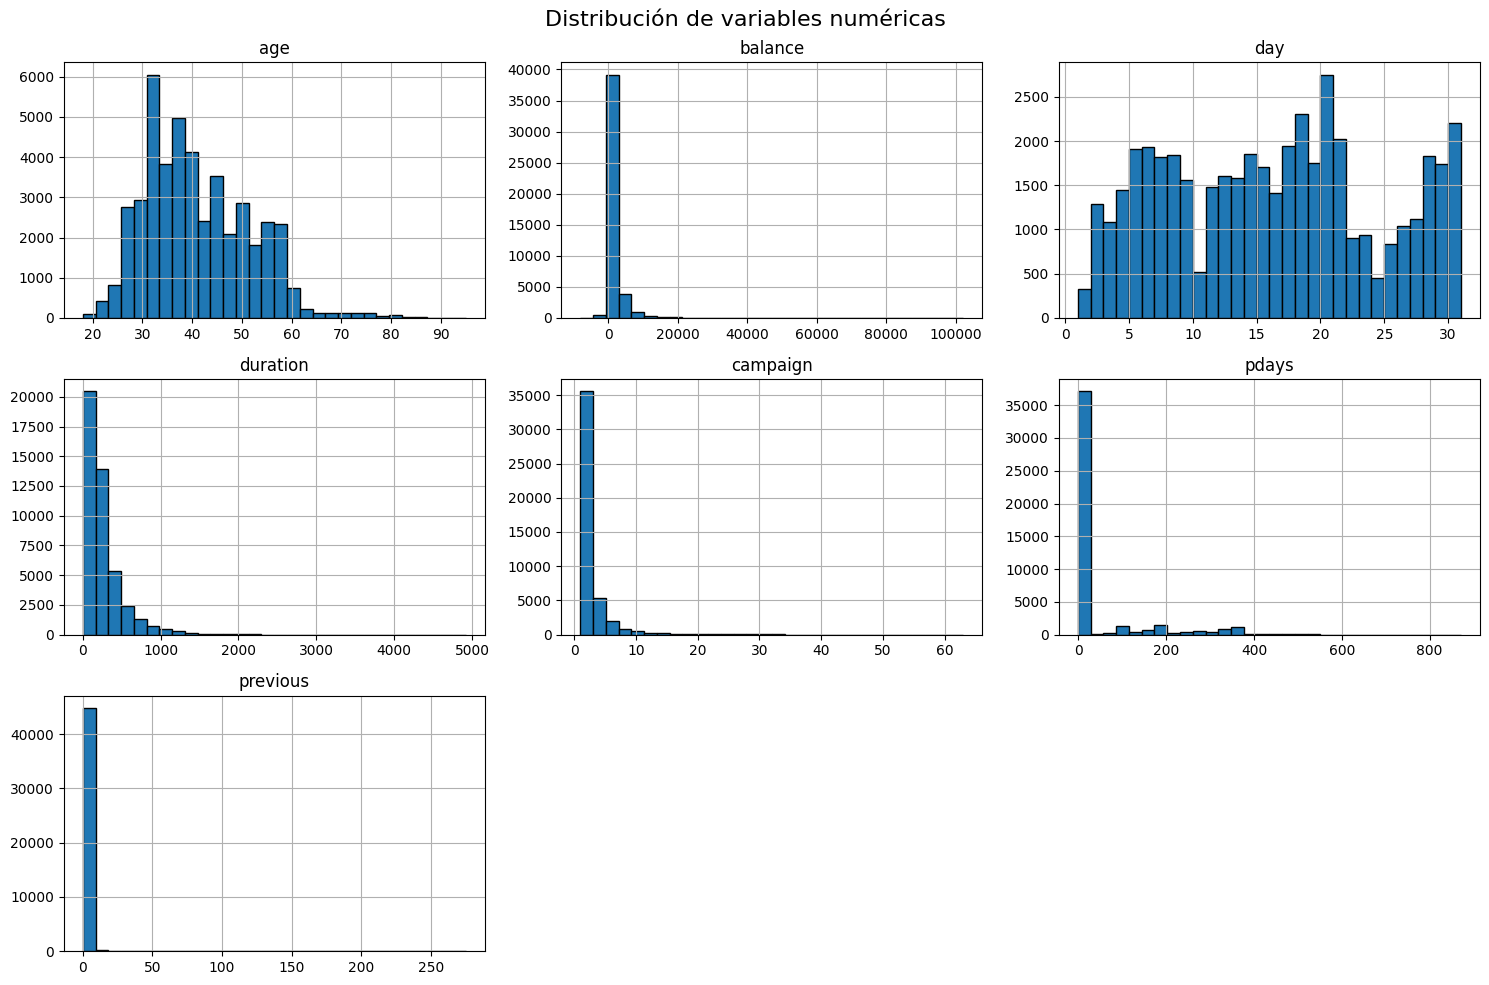

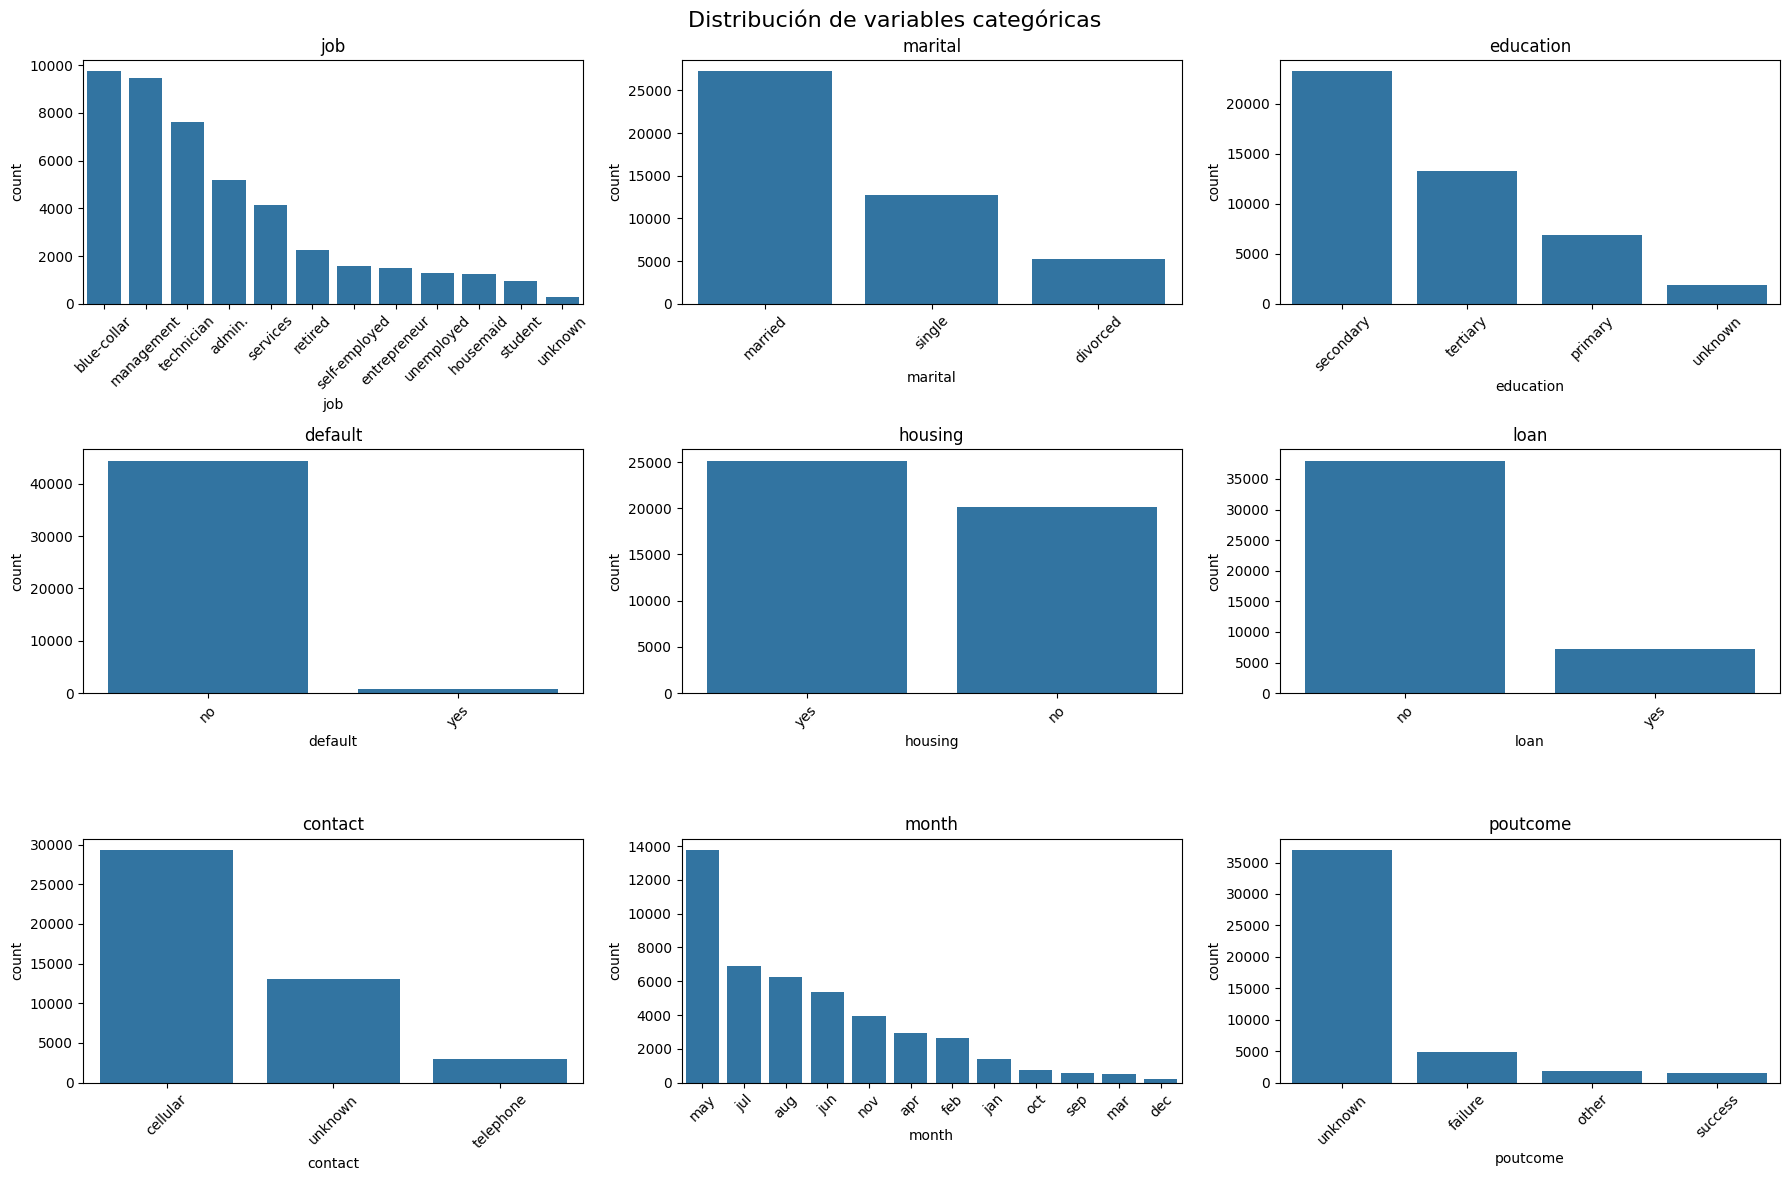

In [ ]:
columnas_numericas = df.select_dtypes(include=np.number).columns.tolist()
columnas_categoricas = [
    c for c in df.select_dtypes(exclude=np.number).columns
    if c != "y"
]

# Distribuciones de variables numéricas
df[columnas_numericas].hist(
    bins=30,
    figsize=(15, 10),
    edgecolor="black"
)
plt.suptitle("Distribución de variables numéricas", fontsize=16)
plt.tight_layout()
plt.show()

# Distribuciones de variables categóricas predictoras
n = len(columnas_categoricas)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
axes = np.array(axes).reshape(-1)

for ax, columna in zip(axes, columnas_categoricas):
    orden = df[columna].value_counts().index
    sns.countplot(data=df, x=columna, order=orden, ax=ax)
    ax.set_title(columna)
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(columnas_categoricas):]:
    ax.remove()

plt.suptitle("Distribución de variables categóricas", fontsize=16)
plt.tight_layout()
plt.show()

## 1.5. Distribución de la variable objetivo

,frecuencia,porcentaje
y,,
no,39922,88.3
yes,5289,11.7


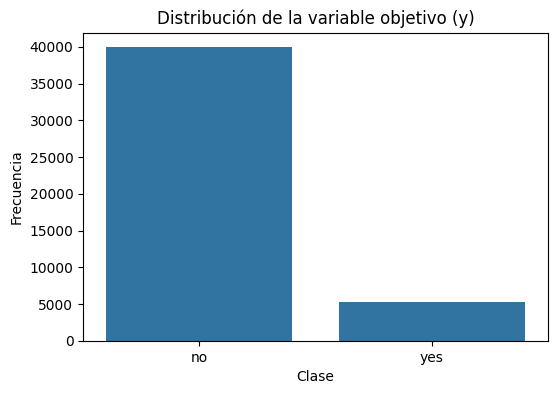

In [ ]:
conteo_y = df["y"].value_counts()
porcentaje_y = df["y"].value_counts(normalize=True).mul(100).round(2)

resumen_y = pd.DataFrame({
    "frecuencia": conteo_y,
    "porcentaje": porcentaje_y
})

display(resumen_y)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y", order=conteo_y.index)
plt.title("Distribución de la variable objetivo (y)")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.show()

## 1.6. Correlaciones y principales hallazgos

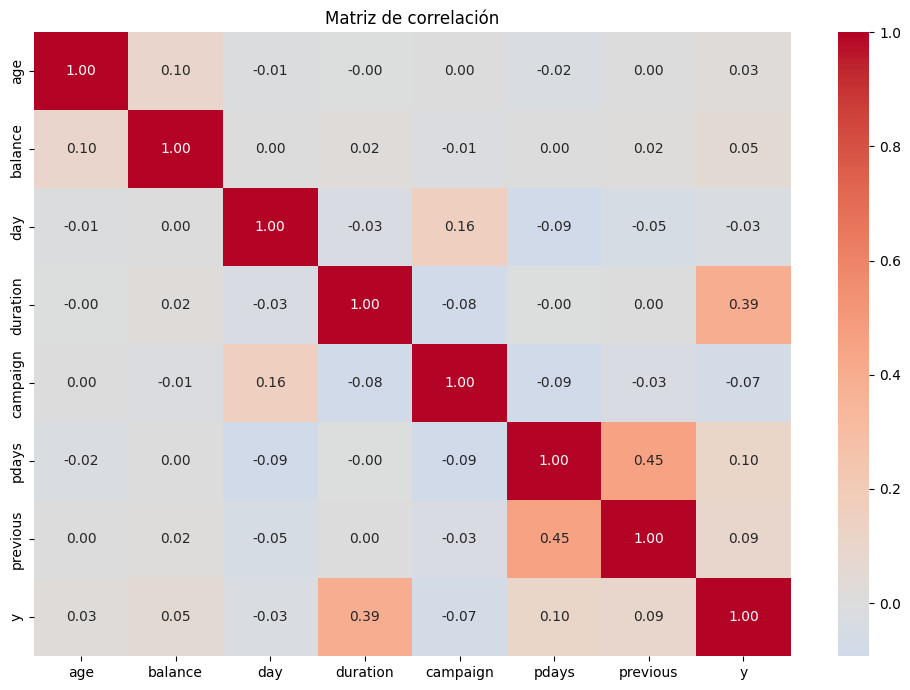

Resumen inicial:
- Registros: 45,211
- Variables: 17
- Valores faltantes totales: 0
- Proporción de la clase positiva: 11.70%

Correlación de variables numéricas con y:


,correlacion_con_y
duration,0.394521
pdays,0.103621
previous,0.093236
campaign,-0.073172
balance,0.052838
day,-0.028348
age,0.025155


In [ ]:
# Correlación entre variables numéricas y la variable objetivo binaria.
df_correlacion = df[columnas_numericas].copy()

y_normalizada = df["y"].astype(str).str.strip().str.lower()
mapa_y = {"yes": 1, "no": 0, "si": 1, "sí": 1}
df_correlacion["y"] = y_normalizada.map(mapa_y)

if df_correlacion["y"].isna().any():
    print("Advertencia: no se pudo convertir completamente 'y' a 0/1.")
    print("Valores encontrados:", df["y"].unique())
    matriz_corr = df[columnas_numericas].corr()
else:
    matriz_corr = df_correlacion.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

print("Resumen inicial:")
print(f"- Registros: {df.shape[0]:,}")
print(f"- Variables: {df.shape[1]}")
print(f"- Valores faltantes totales: {df.isna().sum().sum():,}")

if df_correlacion["y"].notna().all():
    tasa_positiva = df_correlacion["y"].mean() * 100
    print(f"- Proporción de la clase positiva: {tasa_positiva:.2f}%")

    correlaciones_y = (
        matriz_corr["y"]
        .drop("y")
        .sort_values(key=lambda s: s.abs(), ascending=False)
    )
    print("\nCorrelación de variables numéricas con y:")
    display(correlaciones_y.to_frame("correlacion_con_y"))

# 2. Limpieza de datos

## 2.1. Datos faltantes

En esta etapa se verifica la presencia de valores nulos o faltantes en cada variable del dataset. Además, se revisan valores categóricos como "unknown", ya que pueden representar información no disponible.

In [ ]:
# Resumen de valores faltantes
faltantes = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje_nulos": (df.isna().mean() * 100).round(2)
})

# Cadenas vacías en columnas categóricas
columnas_objeto = df.select_dtypes(include="object").columns.tolist()
vacios = pd.Series(
    {c: df[c].astype(str).str.strip().eq("").sum() for c in columnas_objeto},
    name="cadenas_vacias"
)
faltantes = faltantes.join(vacios, how="left").fillna({"cadenas_vacias": 0})
faltantes["cadenas_vacias"] = faltantes["cadenas_vacias"].astype(int)

print("Resumen de valores faltantes:")
display(faltantes)

# Revisión de la categoría explícita "unknown"
unknown = pd.Series(
    {
        c: df[c].astype(str).str.strip().str.lower().eq("unknown").sum()
        for c in columnas_objeto
    },
    name="cantidad_unknown"
)
unknown = unknown[unknown > 0].sort_values(ascending=False)

print("\nCategorías 'unknown' encontradas:")
display(unknown.to_frame())

print(f"\nTotal de valores nulos reales: {int(df.isna().sum().sum())}")
print(f"Total de cadenas vacías: {int(vacios.sum())}")


Resumen de valores faltantes:


,nulos,porcentaje_nulos,cadenas_vacias
age,0,0.0,0
job,0,0.0,0
marital,0,0.0,0
education,0,0.0,0
default,0,0.0,0
balance,0,0.0,0
housing,0,0.0,0
loan,0,0.0,0
contact,0,0.0,0
day,0,0.0,0



Categorías 'unknown' encontradas:


,cantidad_unknown
poutcome,36959
contact,13020
education,1857
job,288



Total de valores nulos reales: 0
Total de cadenas vacías: 0


No se encontraron valores nulos reales en el dataset. Sin embargo, algunas variables categóricas contienen la categoría "unknown", la cual se conserva porque forma parte de la información original y puede ser relevante para el análisis.

## 2.2. Valores atípicos

Se analizan las variables numéricas para identificar posibles valores atípicos mediante el método del rango intercuartílico (IQR) y gráficos de caja. Esto permite reconocer observaciones alejadas del comportamiento general de los datos.

,variable,Q1,Q3,limite_inferior,limite_superior,cantidad_atipicos,porcentaje
0,age,33.0,48.0,10.5,70.5,487,1.08
1,balance,72.0,1428.0,-1962.0,3462.0,4729,10.46
2,duration,103.0,319.0,-221.0,643.0,3235,7.16
3,campaign,1.0,3.0,-2.0,6.0,3064,6.78


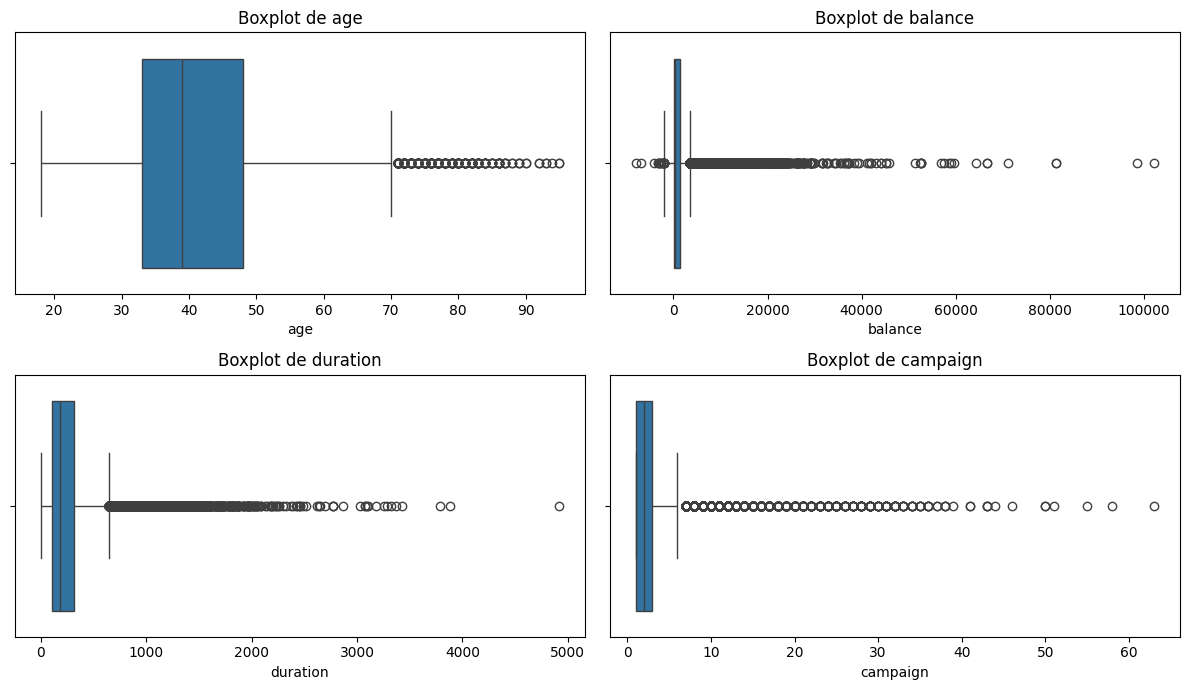

In [ ]:
# Detección de valores atípicos con IQR
variables_iqr = ["age", "balance", "duration", "campaign"]
resumen_atipicos = []

for columna in variables_iqr:
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara = (df[columna] < limite_inferior) | (df[columna] > limite_superior)

    resumen_atipicos.append({
        "variable": columna,
        "Q1": q1,
        "Q3": q3,
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
        "cantidad_atipicos": int(mascara.sum()),
        "porcentaje": round(mascara.mean() * 100, 2)
    })

resumen_atipicos = pd.DataFrame(resumen_atipicos)
display(resumen_atipicos)

# Visualización
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

for ax, columna in zip(axes, variables_iqr):
    sns.boxplot(x=df[columna], ax=ax)
    ax.set_title(f"Boxplot de {columna}")

plt.tight_layout()
plt.show()


Se identificaron valores atípicos en algunas variables numéricas. No obstante, estos valores corresponden a observaciones posibles dentro del contexto del dataset, por lo que no fueron eliminados para evitar pérdida de información relevante.

## 2.3. Tratamiento aplicado

Después de identificar posibles problemas de calidad, se aplican las acciones de limpieza necesarias. Se revisan registros duplicados, valores faltantes, categorías desconocidas y valores extremos antes de decidir si deben modificarse o eliminarse.

In [ ]:
df_limpio = df.copy()
filas_iniciales = len(df_limpio)

# 1) Normalización básica de texto
columnas_categoricas = df_limpio.select_dtypes(include=["object", "string"]).columns.tolist()

for columna in columnas_categoricas:
    df_limpio[columna] = (
        df_limpio[columna]
        .astype("string")
        .str.strip()
        .str.lower()
    )

# 2) Cadenas vacías -> NaN
df_limpio[columnas_categoricas] = df_limpio[columnas_categoricas].replace(
    r"^\s*$", np.nan, regex=True
)

# 3) Eliminar duplicados exactos
duplicados_antes = int(df_limpio.duplicated().sum())
df_limpio = df_limpio.drop_duplicates().copy()

# 4) La variable objetivo no se imputa
filas_y_faltante = int(df_limpio["y"].isna().sum())
df_limpio = df_limpio.dropna(subset=["y"]).copy()

# 5) Imputación solo si aparecieran faltantes reales
columnas_numericas = df_limpio.select_dtypes(include=np.number).columns.tolist()
predictores_categoricos = [
    c for c in df_limpio.select_dtypes(include=["object", "string"]).columns
    if c != "y"
]

for columna in columnas_numericas:
    if df_limpio[columna].isna().any():
        df_limpio[columna] = df_limpio[columna].fillna(
            df_limpio[columna].median()
        )

for columna in predictores_categoricos:
    if df_limpio[columna].isna().any():
        df_limpio[columna] = df_limpio[columna].fillna("unknown")

# 6) Reglas mínimas de dominio: se eliminan solo valores imposibles
mascara_invalida = (
    (df_limpio["age"] <= 0) |
    (df_limpio["age"] > 120) |
    (~df_limpio["day"].between(1, 31)) |
    (df_limpio["duration"] < 0) |
    (df_limpio["campaign"] < 1) |
    (df_limpio["pdays"] < -1) |
    (df_limpio["previous"] < 0)
)

filas_invalidas = int(mascara_invalida.sum())
df_limpio = df_limpio.loc[~mascara_invalida].reset_index(drop=True)

print("Tratamiento aplicado:")
print(f"- Filas iniciales: {filas_iniciales:,}")
print(f"- Duplicados eliminados: {duplicados_antes:,}")
print(f"- Filas eliminadas por y faltante: {filas_y_faltante:,}")
print(f"- Filas eliminadas por valores imposibles: {filas_invalidas:,}")
print(f"- Filas finales: {len(df_limpio):,}")
print("- Los valores atípicos estadísticos válidos se conservaron.")
print("- La categoría 'unknown' se conservó como categoría informativa.")


Tratamiento aplicado:
- Filas iniciales: 45,211
- Duplicados eliminados: 0
- Filas eliminadas por y faltante: 0
- Filas eliminadas por valores imposibles: 0
- Filas finales: 45,211
- Los valores atípicos estadísticos válidos se conservaron.
- La categoría 'unknown' se conservó como categoría informativa.


No fue necesario eliminar registros, ya que no se encontraron datos nulos, duplicados ni valores claramente inválidos. Las categorías "unknown" y los valores extremos válidos se conservaron para mantener la integridad y representatividad del dataset origina

## 2.4. Validación del dataset limpio

Finalmente, se valida el resultado de la limpieza comprobando nuevamente las dimensiones del dataset, la existencia de valores nulos, duplicados y la consistencia de sus variables.

In [ ]:
# Validaciones finales
validaciones = pd.Series({
    "Sin valores nulos": df_limpio.isna().sum().sum() == 0,
    "Sin duplicados": df_limpio.duplicated().sum() == 0,
    "Edad en rango válido": df_limpio["age"].between(1, 120).all(),
    "Día en rango 1-31": df_limpio["day"].between(1, 31).all(),
    "Duración no negativa": (df_limpio["duration"] >= 0).all(),
    "Campaign >= 1": (df_limpio["campaign"] >= 1).all(),
    "Pdays >= -1": (df_limpio["pdays"] >= -1).all(),
    "Previous >= 0": (df_limpio["previous"] >= 0).all(),
    "Objetivo y válido": set(df_limpio["y"].dropna().unique()).issubset({"yes", "no"})
})

display(validaciones.to_frame("cumple"))

print(f"Dimensiones originales: {df.shape}")
print(f"Dimensiones después de la limpieza: {df_limpio.shape}")

print("\nDistribución de la variable objetivo después de la limpieza:")
display(
    pd.DataFrame({
        "frecuencia": df_limpio["y"].value_counts(),
        "porcentaje": (
            df_limpio["y"].value_counts(normalize=True) * 100
        ).round(2)
    })
)

if not validaciones.all():
    raise ValueError("La validación final detectó al menos un problema.")

# Se entrega el dataset limpio a la siguiente sección del laboratorio
df = df_limpio.copy()

print("\nValidación completada: el dataset está listo para la transformación de datos.")


,cumple
Sin valores nulos,True
Sin duplicados,True
Edad en rango válido,True
Día en rango 1-31,True
Duración no negativa,True
Campaign >= 1,True
Pdays >= -1,True
Previous >= 0,True
Objetivo y válido,True


Dimensiones originales: (45211, 17)
Dimensiones después de la limpieza: (45211, 17)

Distribución de la variable objetivo después de la limpieza:


,frecuencia,porcentaje
y,,
no,39922,88.3
yes,5289,11.7



Validación completada: el dataset está listo para la transformación de datos.


El dataset final mantiene 45 211 registros y 17 variables, sin valores nulos ni registros duplicados. Por lo tanto, los datos quedan consistentes y preparados para continuar con la etapa de transformación

# 3. Transformación de datos

## 3.1. Codificación de variables categóricas

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Separar la variable objetivo (y) de las variables predictoras (X)
X = df.drop("y", axis=1)
y = df["y"].map({"no": 0, "yes": 1})

# 2. Mapeo binario manual para variables categóricas de 2 valores (sí/no)
variables_binarias = ["default", "housing", "loan"]
for col in variables_binarias:
    X[col] = X[col].map({"no": 0, "yes": 1})

# 3. One-Hot Encoding para las demás variables
# Al no especificar 'columns', pandas detectará y codificará automáticamente
# cualquier variable tipo 'object', 'string' o 'category'.
X_encoded = pd.get_dummies(X, drop_first=True)

# 4. Convertir los valores booleanos generados a enteros (0 y 1)
X_encoded = X_encoded.astype(int)

print(f"Dimensiones de X original: {X.shape}")
print(f"Dimensiones de X codificado: {X_encoded.shape}")
display(X_encoded.head())

Dimensiones de X original: (45211, 16)
Dimensiones de X codificado: (45211, 42)


,age,default,balance,housing,loan,day,duration,campaign,pdays,previous,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,58,0,2143,1,0,5,261,1,-1,0,...,0,0,0,1,0,0,0,0,0,1
1,44,0,29,1,0,5,151,1,-1,0,...,0,0,0,1,0,0,0,0,0,1
2,33,0,2,1,1,5,76,1,-1,0,...,0,0,0,1,0,0,0,0,0,1
3,47,0,1506,1,0,5,92,1,-1,0,...,0,0,0,1,0,0,0,0,0,1
4,33,0,1,0,0,5,198,1,-1,0,...,0,0,0,1,0,0,0,0,0,1


## 3.2. Normalización

In [ ]:
scaler_norm = MinMaxScaler()

# Crear una copia para mantener los datos organizados
X_norm = X_encoded.copy()

# Aplicar la normalización únicamente a las variables numéricas originales
X_norm[columnas_numericas] = scaler_norm.fit_transform(X_norm[columnas_numericas])

print("Estadísticas de datos normalizados (Rango [0, 1]):")
display(X_norm[columnas_numericas].describe().round(4).T)

Estadísticas de datos normalizados (Rango [0, 1]):


,count,mean,std,min,25%,50%,75%,max
age,45211.0,0.2979,0.1379,0.0,0.1948,0.2727,0.3896,1.0
balance,45211.0,0.0852,0.0276,0.0,0.0735,0.0769,0.0858,1.0
day,45211.0,0.4935,0.2774,0.0,0.2333,0.5000,0.6667,1.0
duration,45211.0,0.0525,0.0524,0.0,0.0209,0.0366,0.0649,1.0
campaign,45211.0,0.0284,0.0500,0.0,0.0000,0.0161,0.0323,1.0
pdays,45211.0,0.0472,0.1148,0.0,0.0000,0.0000,0.0000,1.0
previous,45211.0,0.0021,0.0084,0.0,0.0000,0.0000,0.0000,1.0


## 3.3. Estandarización

In [ ]:
scaler_std = StandardScaler()

# Crear una copia para la estandarización
X_std = X_encoded.copy()

# Aplicar la estandarización únicamente a las variables numéricas originales
X_std[columnas_numericas] = scaler_std.fit_transform(X_std[columnas_numericas])

print("Estadísticas de datos estandarizados (Media ≈ 0, Desviación Estándar ≈ 1):")
display(X_std[columnas_numericas].describe().round(4).T)

Estadísticas de datos estandarizados (Media ≈ 0, Desviación Estándar ≈ 1):


,count,mean,std,min,25%,50%,75%,max
age,45211.0,0.0,1.0,-2.1600,-0.7474,-0.1823,0.6652,5.0914
balance,45211.0,0.0,1.0,-3.0811,-0.4238,-0.3003,0.0216,33.0948
day,45211.0,0.0,1.0,-1.7791,-0.9380,0.0233,0.6240,1.8256
duration,45211.0,0.0,1.0,-1.0025,-0.6025,-0.3035,0.2362,18.0947
campaign,45211.0,0.0,1.0,-0.5694,-0.5694,-0.2466,0.0762,19.4436
pdays,45211.0,0.0,1.0,-0.4115,-0.4115,-0.4115,-0.4115,8.2974
previous,45211.0,0.0,1.0,-0.2519,-0.2519,-0.2519,-0.2519,119.1360


## 3.4. Comparación y selección de transformación

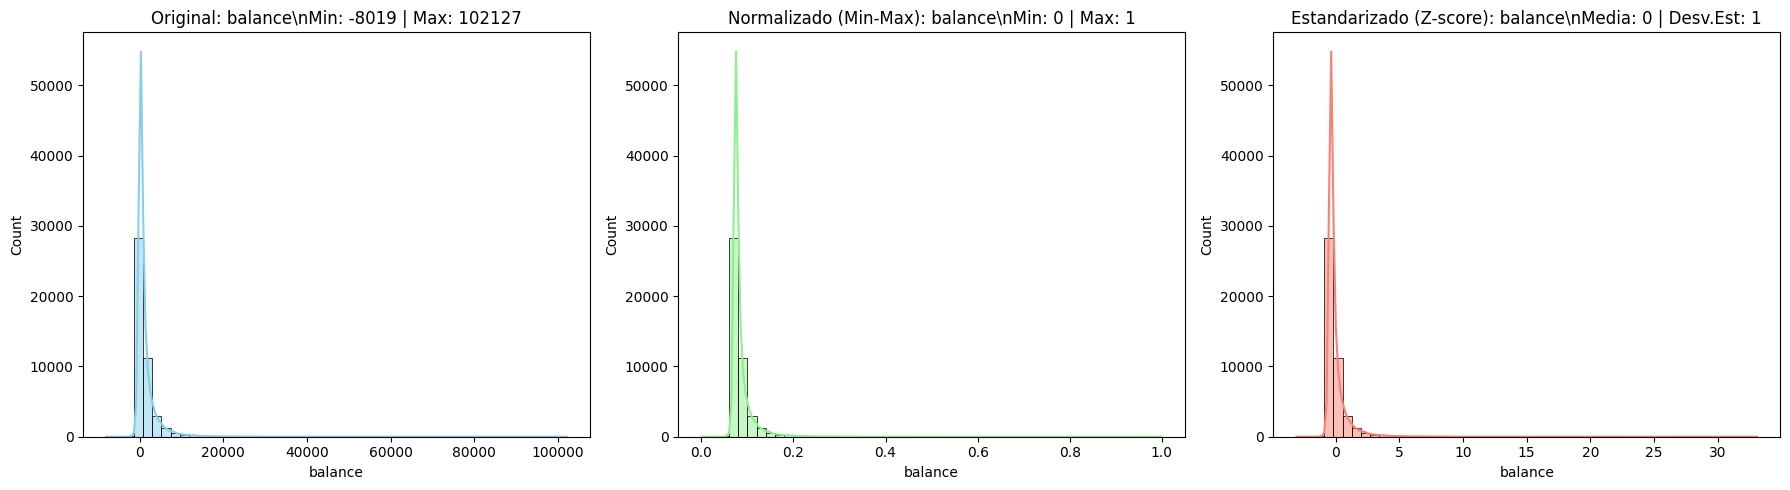

\n=> Se selecciona el conjunto estandarizado (X_std) para proceder con el entrenamiento de modelos.


In [ ]:
columna_ejemplo = "balance"

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribución Original
sns.histplot(X_encoded[columna_ejemplo], bins=50, kde=True, ax=axes[0], color="skyblue")
axes[0].set_title(f"Original: {columna_ejemplo}\\nMin: {X_encoded[columna_ejemplo].min()} | Max: {X_encoded[columna_ejemplo].max()}")

# Distribución Normalizada
sns.histplot(X_norm[columna_ejemplo], bins=50, kde=True, ax=axes[1], color="lightgreen")
axes[1].set_title(f"Normalizado (Min-Max): {columna_ejemplo}\\nMin: 0 | Max: 1")

# Distribución Estandarizada
sns.histplot(X_std[columna_ejemplo], bins=50, kde=True, ax=axes[2], color="salmon")
axes[2].set_title(f"Estandarizado (Z-score): {columna_ejemplo}\\nMedia: 0 | Desv.Est: 1")

plt.tight_layout()
plt.show()

# SELECCIÓN FINAL DE DATOS
print("\\n=> Se selecciona el conjunto estandarizado (X_std) para proceder con el entrenamiento de modelos.")
X_final = X_std.copy()

# 4. Feature Engineering

## 4.1. Creación y transformación de características

In [ ]:

X_fe = X.copy()

X_fe["balance_log"] = (
    np.sign(X_fe["balance"]) *
    np.log1p(np.abs(X_fe["balance"]))
)


X_fe["campaign_log"] = np.log1p(X_fe["campaign"])
X_fe["previous_log"] = np.log1p(X_fe["previous"])

X_fe["contactado_antes"] = (X_fe["pdays"] != -1).astype(int)


pdays_ajustado = X_fe["pdays"].replace(-1, 0)
X_fe["pdays_log"] = np.log1p(pdays_ajustado)

mapa_mes = {
    "jan": 1, "feb": 2, "mar": 3, "apr": 4,
    "may": 5, "jun": 6, "jul": 7, "aug": 8,
    "sep": 9, "oct": 10, "nov": 11, "dec": 12
}

mes_num = X_fe["month"].map(mapa_mes)

X_fe["mes_sin"] = np.sin(2 * np.pi * mes_num / 12)
X_fe["mes_cos"] = np.cos(2 * np.pi * mes_num / 12)

X_fe["dia_sin"] = np.sin(2 * np.pi * X_fe["day"] / 31)
X_fe["dia_cos"] = np.cos(2 * np.pi * X_fe["day"] / 31)

print("Nuevas características creadas:")
nuevas_caracteristicas = [
    "balance_log",
    "campaign_log",
    "previous_log",
    "contactado_antes",
    "pdays_log",
    "mes_sin",
    "mes_cos",
    "dia_sin",
    "dia_cos"
]

display(X_fe[nuevas_caracteristicas].head())

Nuevas características creadas:


,balance_log,campaign_log,previous_log,contactado_antes,pdays_log,mes_sin,mes_cos,dia_sin,dia_cos
0,7.670429,0.693147,0.0,0,0.0,0.5,-0.866025,0.848644,0.528964
1,3.401197,0.693147,0.0,0,0.0,0.5,-0.866025,0.848644,0.528964
2,1.098612,0.693147,0.0,0,0.0,0.5,-0.866025,0.848644,0.528964
3,7.317876,0.693147,0.0,0,0.0,0.5,-0.866025,0.848644,0.528964
4,0.693147,0.693147,0.0,0,0.0,0.5,-0.866025,0.848644,0.528964


## 4.2. Eliminación de variables innecesarias

In [ ]:
variables_eliminar = [
    "balance",
    "campaign",
    "previous",
    "pdays",
    "month",
    "day",
    "duration"
]

X_fe_reducido = X_fe.drop(columns=variables_eliminar).copy()

print("Variables eliminadas:")
for variable in variables_eliminar:
    print(f"- {variable}")

print(f"\nNúmero de variables antes de la eliminación: {X_fe.shape[1]}")
print(f"Número de variables después de la eliminación: {X_fe_reducido.shape[1]}")

display(X_fe_reducido.head())

Variables eliminadas:
- balance
- campaign
- previous
- pdays
- month
- day
- duration

Número de variables antes de la eliminación: 25
Número de variables después de la eliminación: 18


,age,job,marital,education,default,housing,loan,contact,poutcome,balance_log,campaign_log,previous_log,contactado_antes,pdays_log,mes_sin,mes_cos,dia_sin,dia_cos
0,58,management,married,tertiary,0,1,0,unknown,unknown,7.670429,0.693147,0.0,0,0.0,0.5,-0.866025,0.848644,0.528964
1,44,technician,single,secondary,0,1,0,unknown,unknown,3.401197,0.693147,0.0,0,0.0,0.5,-0.866025,0.848644,0.528964
2,33,entrepreneur,married,secondary,0,1,1,unknown,unknown,1.098612,0.693147,0.0,0,0.0,0.5,-0.866025,0.848644,0.528964
3,47,blue-collar,married,unknown,0,1,0,unknown,unknown,7.317876,0.693147,0.0,0,0.0,0.5,-0.866025,0.848644,0.528964
4,33,unknown,single,unknown,0,0,0,unknown,unknown,0.693147,0.693147,0.0,0,0.0,0.5,-0.866025,0.848644,0.528964


## 4.3. Dataset resultante

In [ ]:
X_fe_final = pd.get_dummies(
    X_fe_reducido,
    drop_first=True,
    dtype=int
)

variables_continuas_fe = [
    "age",
    "balance_log",
    "campaign_log",
    "previous_log",
    "pdays_log",
    "mes_sin",
    "mes_cos",
    "dia_sin",
    "dia_cos"
]

df_fe_final = X_fe_final.copy()
df_fe_final["y"] = y.values

print("Dataset resultante del Feature Engineering")
print(f"Filas: {df_fe_final.shape[0]:,}")
print(f"Columnas predictoras: {X_fe_final.shape[1]}")
print(f"Columnas totales incluyendo y: {df_fe_final.shape[1]}")

print("\nTipos de datos:")
print(df_fe_final.dtypes.value_counts())

print("\nDistribución de la variable objetivo:")
display(
    pd.DataFrame({
        "frecuencia": y.value_counts(),
        "porcentaje": (y.value_counts(normalize=True) * 100).round(2)
    })
)

print("\nPrimeras filas del dataset resultante:")
display(df_fe_final.head())

Dataset resultante del Feature Engineering
Filas: 45,211
Columnas predictoras: 34
Columnas totales incluyendo y: 35

Tipos de datos:
int64      27
float64     8
Name: count, dtype: int64

Distribución de la variable objetivo:


,frecuencia,porcentaje
y,,
0,39922,88.3
1,5289,11.7



Primeras filas del dataset resultante:


,age,default,housing,loan,balance_log,campaign_log,previous_log,contactado_antes,pdays_log,mes_sin,...,marital_single,education_secondary,education_tertiary,education_unknown,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown,y
0,58,0,1,0,7.670429,0.693147,0.0,0,0.0,0.5,...,0,0,1,0,0,1,0,0,1,0
1,44,0,1,0,3.401197,0.693147,0.0,0,0.0,0.5,...,1,1,0,0,0,1,0,0,1,0
2,33,0,1,1,1.098612,0.693147,0.0,0,0.0,0.5,...,0,1,0,0,0,1,0,0,1,0
3,47,0,1,0,7.317876,0.693147,0.0,0,0.0,0.5,...,0,0,0,1,0,1,0,0,1,0
4,33,0,0,0,0.693147,0.693147,0.0,0,0.0,0.5,...,1,0,0,1,0,1,0,0,1,0


# 5. Preparación para el balanceo

## 5.1. Separación de variables predictoras y objetivo

In [ ]:
%pip install -q "scikit-learn==1.6.0" "imbalanced-learn==0.13.0" "imbalanced-ensemble==0.2.3"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.6/41.6 kB 1.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 58.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 238.4/238.4 kB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 752.0/752.0 kB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.4/160.4 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.8/93.8 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 81.9 MB/s eta 0:00:00


In [ ]:
X = X_fe_final.copy().astype(float)
y = y.copy()

print(f"Dimensiones de X (predictoras): {X.shape}")
print(f"Longitud de y (objetivo): {y.shape[0]}")

Dimensiones de X (predictoras): (45211, 34)
Longitud de y (objetivo): 45211


## 5.2. División entrenamiento/prueba

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Partición estratificada en Train (80%) y Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 2. Identificación de variables continuas definidas en la Sección 4.3
variables_continuas = [
    "age", "balance_log", "campaign_log", "previous_log",
    "pdays_log", "mes_sin", "mes_cos", "dia_sin", "dia_cos"
]

# 3. Estandarización de variables continuas sin fuga de información
scaler = StandardScaler()

# Ajustar únicamente en entrenamiento y transformar ambos conjuntos
X_train[variables_continuas] = scaler.fit_transform(X_train[variables_continuas])
X_test[variables_continuas] = scaler.transform(X_test[variables_continuas])

print(f"Tamaño de X_train: {X_train.shape}")
print(f"Tamaño de X_test:  {X_test.shape}")

Tamaño de X_train: (36168, 34)
Tamaño de X_test:  (9043, 34)


## 5.3. Distribución inicial de clases

Distribución en Entrenamiento (y_train):


,Frecuencia,Porcentaje (%)
y,,
0,31937,88.3
1,4231,11.7


/tmp/ipykernel_1846/4277715991.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conteo.index, y=conteo.values, palette="Blues_r")


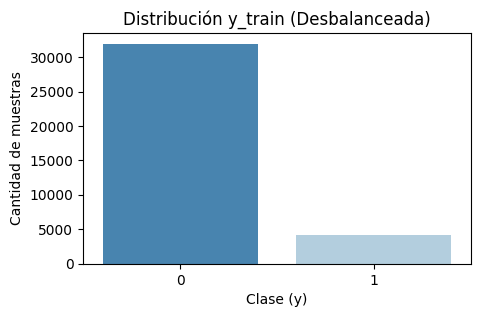

Distribución en Prueba (y_test):


,Frecuencia,Porcentaje (%)
y,,
0,7985,88.3
1,1058,11.7


/tmp/ipykernel_1846/4277715991.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=conteo.index, y=conteo.values, palette="Blues_r")


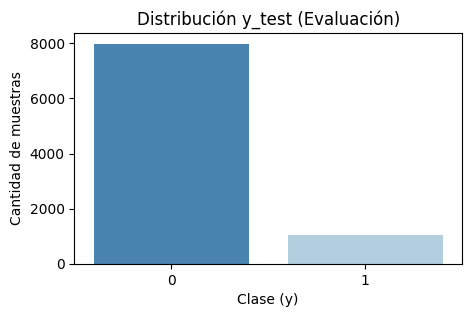

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def mostrar_distribucion(vector_y, titulo="Distribución de Clases"):
    conteo = vector_y.value_counts()
    porcentaje = vector_y.value_counts(normalize=True).mul(100).round(2)
    tabla = pd.DataFrame({"Frecuencia": conteo, "Porcentaje (%)": porcentaje})
    display(tabla)

    plt.figure(figsize=(5, 3))
    sns.barplot(x=conteo.index, y=conteo.values, palette="Blues_r")
    plt.title(titulo)
    plt.xlabel("Clase (y)")
    plt.ylabel("Cantidad de muestras")
    plt.show()

print("Distribución en Entrenamiento (y_train):")
mostrar_distribucion(y_train, "Distribución y_train (Desbalanceada)")

print("Distribución en Prueba (y_test):")
mostrar_distribucion(y_test, "Distribución y_test (Evaluación)")

## 5.4. Modelo base sin balanceo

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

resultados_metricas = []
matrices_tecnicas = {}


def evaluar_tecnica(
    modelo, X_tr, y_tr, X_te, y_te,
    nombre_tecnica, entrenar=True
):
    if entrenar:
        modelo.fit(X_tr, y_tr)

    y_pred = modelo.predict(X_te)
    indice_positivo = list(modelo.classes_).index(1)
    y_proba = modelo.predict_proba(X_te)[:, indice_positivo]

    fila = {
        "Técnica": nombre_tecnica,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred, zero_division=0),
        "Recall": recall_score(y_te, y_pred, zero_division=0),
        "F1-Score": f1_score(y_te, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_te, y_proba)
    }

    # Reemplazar el resultado si esta técnica ya fue evaluada.
    resultados_metricas[:] = [
        r for r in resultados_metricas
        if r["Técnica"] != nombre_tecnica
    ]
    resultados_metricas.append(fila)

    matriz = confusion_matrix(y_te, y_pred, labels=[0, 1])
    matrices_tecnicas[nombre_tecnica] = matriz

    display(
        pd.DataFrame([fila])
        .set_index("Técnica")
        .round(4)
    )

    print("Matriz de confusión [0=no, 1=yes]:")
    print(matriz)

    print(classification_report(
        y_te, y_pred,
        labels=[0, 1],
        digits=4,
        zero_division=0
    ))


modelo_base = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

evaluar_tecnica(
    modelo_base,
    X_train, y_train,
    X_test, y_test,
    "Modelo Base (Sin Balanceo)"
)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
Modelo Base (Sin Balanceo),0.8937,0.6398,0.2098,0.316,0.7896


Matriz de confusión [0=no, 1=yes]:
[[7860  125]
 [ 836  222]]
              precision    recall  f1-score   support

           0     0.9039    0.9843    0.9424      7985
           1     0.6398    0.2098    0.3160      1058

    accuracy                         0.8937      9043
   macro avg     0.7718    0.5971    0.6292      9043
weighted avg     0.8730    0.8937    0.8691      9043



# 6. Aplicación de técnicas de balanceo

## 6.1. SMOTE

- Aplicación
- Distribución resultante
- Métricas
- Fortalezas observadas
- Debilidades observadas

In [ ]:
from imblearn.over_sampling import SMOTE

# Aplicación
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Distribución resultante
print("Distribución tras SMOTE:")
print(pd.Series(y_train_smote).value_counts())

# Métricas
modelo_smote = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
evaluar_tecnica(modelo_smote, X_train_smote, y_train_smote, X_test, y_test, "SMOTE")

Distribución tras SMOTE:
y
0    31937
1    31937
Name: count, dtype: int64


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
SMOTE,0.8904,0.5585,0.3025,0.3924,0.7881


Matriz de confusión [0=no, 1=yes]:
[[7732  253]
 [ 738  320]]
              precision    recall  f1-score   support

           0     0.9129    0.9683    0.9398      7985
           1     0.5585    0.3025    0.3924      1058

    accuracy                         0.8904      9043
   macro avg     0.7357    0.6354    0.6661      9043
weighted avg     0.8714    0.8904    0.8757      9043



### Fortalezas observadas

- El Recall aumentó de **20,98% a 30,25%** respecto al modelo base, mejorando la detección de clientes que suscribieron el depósito.
- El F1-Score aumentó de **0,3160 a 0,3924**, mostrando una mejora en el equilibrio entre precisión y sensibilidad para la clase positiva.

### Debilidades observadas

- La Precision disminuyó de **63,98% a 55,85%**: una menor proporción de las predicciones positivas fue correcta.
- El ROC-AUC pasó de **0,7896 a 0,7881**. Por tanto, el aumento de Recall y F1 no estuvo acompañado de una mejora en la capacidad de ordenar los casos positivos por encima de los negativos.

## 6.2. ADASYN

- Aplicación
- Distribución resultante
- Métricas
- Fortalezas observadas
- Debilidades observadas

In [ ]:
from imblearn.over_sampling import ADASYN

# Aplicación
adasyn = ADASYN(random_state=42, n_neighbors=5)
X_train_adasyn, y_train_adasyn = adasyn.fit_resample(X_train, y_train)

# Distribución resultante
print("Distribución tras ADASYN:")
print(pd.Series(y_train_adasyn).value_counts())

# Métricas
modelo_adasyn = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
evaluar_tecnica(modelo_adasyn, X_train_adasyn, y_train_adasyn, X_test, y_test, "ADASYN")

Distribución tras ADASYN:
y
0    31937
1    31931
Name: count, dtype: int64


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
ADASYN,0.8883,0.5427,0.2883,0.3765,0.7887


Matriz de confusión [0=no, 1=yes]:
[[7728  257]
 [ 753  305]]
              precision    recall  f1-score   support

           0     0.9112    0.9678    0.9387      7985
           1     0.5427    0.2883    0.3765      1058

    accuracy                         0.8883      9043
   macro avg     0.7270    0.6280    0.6576      9043
weighted avg     0.8681    0.8883    0.8729      9043



### Fortalezas observadas

- El Recall aumentó de **20,98% a 28,83%**, permitiendo detectar una mayor proporción de clientes de la clase positiva.
- El F1-Score aumentó de **0,3160 a 0,3765**, mejorando el resultado del modelo base para esta clase.

### Debilidades observadas

- La Precision disminuyó de **63,98% a 54,27%**, mientras que el ROC-AUC pasó de **0,7896 a 0,7887**.
- En esta ejecución, ADASYN obtuvo un Recall y un F1-Score inferiores a SMOTE: **28,83% frente a 30,25%** y **0,3765 frente a 0,3924**, respectivamente.

## 6.3. Random Over Sampling

- Aplicación
- Distribución resultante
- Métricas
- Fortalezas observadas
- Debilidades observadas

In [ ]:
from imblearn.over_sampling import RandomOverSampler

# Aplicación
ros = RandomOverSampler(random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(X_train, y_train)

# Distribución resultante
print("Distribución tras Random Over Sampling:")
print(pd.Series(y_train_ros).value_counts())

# Métricas
modelo_ros = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
evaluar_tecnica(modelo_ros, X_train_ros, y_train_ros, X_test, y_test, "Random Over Sampling")

Distribución tras Random Over Sampling:
y
0    31937
1    31937
Name: count, dtype: int64


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
Random Over Sampling,0.8873,0.5344,0.2864,0.3729,0.7896


Matriz de confusión [0=no, 1=yes]:
[[7721  264]
 [ 755  303]]
              precision    recall  f1-score   support

           0     0.9109    0.9669    0.9381      7985
           1     0.5344    0.2864    0.3729      1058

    accuracy                         0.8873      9043
   macro avg     0.7227    0.6267    0.6555      9043
weighted avg     0.8669    0.8873    0.8720      9043



### Fortalezas observadas

- El Recall aumentó de **20,98% a 28,64%**, y el F1-Score pasó de **0,3160 a 0,3729**.
- La distribución de entrenamiento quedó equilibrada con **31.937 ejemplos por clase**, mediante duplicación de observaciones existentes, sin crear combinaciones sintéticas de atributos.

### Debilidades observadas

- La Precision disminuyó de **63,98% a 53,44%**, y la Accuracy pasó de **89,37% a 88,73%**.
- El ROC-AUC se mantuvo en **0,7896**, a la precisión mostrada. Además, el Recall de **28,64%** indica que todavía no se detectó la mayoría de los casos positivos.

## 6.4. Borderline-SMOTE

- Aplicación
- Distribución resultante
- Métricas
- Fortalezas observadas
- Debilidades observadas

In [ ]:
from imblearn.over_sampling import BorderlineSMOTE

# Aplicación
bsmote = BorderlineSMOTE(random_state=42, k_neighbors=5, m_neighbors=10, kind="borderline-1")
X_train_bsmote, y_train_bsmote = bsmote.fit_resample(X_train, y_train)

# Distribución resultante
print("Distribución tras Borderline-SMOTE:")
print(pd.Series(y_train_bsmote).value_counts())

# Métricas
modelo_bsmote = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
evaluar_tecnica(modelo_bsmote, X_train_bsmote, y_train_bsmote, X_test, y_test, "Borderline-SMOTE")

Distribución tras Borderline-SMOTE:
y
0    31937
1    31937
Name: count, dtype: int64


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
Borderline-SMOTE,0.8859,0.5227,0.2826,0.3669,0.7874


Matriz de confusión [0=no, 1=yes]:
[[7712  273]
 [ 759  299]]
              precision    recall  f1-score   support

           0     0.9104    0.9658    0.9373      7985
           1     0.5227    0.2826    0.3669      1058

    accuracy                         0.8859      9043
   macro avg     0.7166    0.6242    0.6521      9043
weighted avg     0.8650    0.8859    0.8706      9043



### Fortalezas observadas

- El Recall aumentó de **20,98% a 28,26%**, mejorando la detección de la clase positiva respecto al modelo base.
- El F1-Score aumentó de **0,3160 a 0,3669**, aunque la mejora fue menor que la obtenida con SMOTE.

### Debilidades observadas

- La Precision disminuyó de **63,98% a 52,27%**, y el ROC-AUC pasó de **0,7896 a 0,7874**.
- El enfoque en ejemplos cercanos a la frontera no produjo mejores resultados que SMOTE en esta ejecución: obtuvo menor Recall (**28,26% frente a 30,25%**) y menor F1-Score (**0,3669 frente a 0,3924**).

## 6.5. SVM-SMOTE

- Aplicación
- Distribución resultante
- Métricas
- Fortalezas observadas
- Debilidades observadas

In [ ]:
from imblearn.over_sampling import SVMSMOTE

# Aplicación
svm_smote = SVMSMOTE(random_state=42, k_neighbors=5, m_neighbors=10, svm_estimator=None)
X_train_svm, y_train_svm = svm_smote.fit_resample(X_train, y_train)

# Distribución resultante
print("Distribución tras SVM-SMOTE:")
print(pd.Series(y_train_svm).value_counts())

# Métricas
modelo_svm_smote = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
evaluar_tecnica(modelo_svm_smote, X_train_svm, y_train_svm, X_test, y_test, "SVM-SMOTE")

Distribución tras SVM-SMOTE:
y
0    31937
1    31937
Name: count, dtype: int64


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
SVM-SMOTE,0.887,0.5281,0.3195,0.3981,0.7976


Matriz de confusión [0=no, 1=yes]:
[[7683  302]
 [ 720  338]]
              precision    recall  f1-score   support

           0     0.9143    0.9622    0.9376      7985
           1     0.5281    0.3195    0.3981      1058

    accuracy                         0.8870      9043
   macro avg     0.7212    0.6408    0.6679      9043
weighted avg     0.8691    0.8870    0.8745      9043



### Fortalezas observadas

- El Recall aumentó de **20,98% a 31,95%**, y el F1-Score pasó de **0,3160 a 0,3981**.
- Obtuvo el mayor ROC-AUC entre las diez técnicas evaluadas en esta ejecución: **0,7976**, frente a **0,7896** del modelo base.

### Debilidades observadas

- La Precision disminuyó de **63,98% a 52,81%**, y la Accuracy pasó de **89,37% a 88,70%**.
- Aunque mejoró el Recall, dejó **720 falsos negativos** y produjo **302 falsos positivos**. Por tanto, todavía no identificó la mayoría de los clientes de la clase positiva.

## 6.6. KMeans-SMOTE

- Aplicación
- Distribución resultante
- Métricas
- Fortalezas observadas
- Debilidades observadas

In [ ]:
from imblearn.over_sampling import KMeansSMOTE

# Aplicación
kmeans_smote = KMeansSMOTE(
    random_state=42,
    k_neighbors=5,
    cluster_balance_threshold=0.01,
    density_exponent='auto'
)
X_train_km, y_train_km = kmeans_smote.fit_resample(X_train, y_train)

# Distribución resultante
print("Distribución tras KMeans-SMOTE:")
print(pd.Series(y_train_km).value_counts())

# Métricas
modelo_km_smote = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
evaluar_tecnica(modelo_km_smote, X_train_km, y_train_km, X_test, y_test, "KMeans-SMOTE")

Distribución tras KMeans-SMOTE:
y
1    31943
0    31937
Name: count, dtype: int64


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
KMeans-SMOTE,0.8914,0.5826,0.2533,0.3531,0.7909


Matriz de confusión [0=no, 1=yes]:
[[7793  192]
 [ 790  268]]
              precision    recall  f1-score   support

           0     0.9080    0.9760    0.9407      7985
           1     0.5826    0.2533    0.3531      1058

    accuracy                         0.8914      9043
   macro avg     0.7453    0.6146    0.6469      9043
weighted avg     0.8699    0.8914    0.8720      9043



### Fortalezas observadas

- El Recall aumentó de **20,98% a 25,33%**, y el F1-Score pasó de **0,3160 a 0,3531**.
- El ROC-AUC aumentó ligeramente de **0,7896 a 0,7909**. La distribución de entrenamiento quedó prácticamente equilibrada, con **31.937 negativos y 31.943 positivos**.

### Debilidades observadas

- La Precision disminuyó de **63,98% a 58,26%**. El modelo dejó **790 falsos negativos** y produjo **192 falsos positivos**.
- La mejora de sensibilidad fue limitada: con un Recall de **25,33%**, aproximadamente tres de cada cuatro casos positivos no fueron detectados.

## 6.7. SMOTE-Tomek

- Aplicación
- Distribución resultante
- Métricas
- Fortalezas observadas
- Debilidades observadas

In [ ]:
from imblearn.combine import SMOTETomek

# Aplicación
smote_tomek = SMOTETomek(random_state=42)
X_train_st, y_train_st = smote_tomek.fit_resample(X_train, y_train)

# Distribución resultante
print("Distribución tras SMOTE-Tomek:")
print(pd.Series(y_train_st).value_counts())

# Métricas
modelo_smote_tomek = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
evaluar_tecnica(modelo_smote_tomek, X_train_st, y_train_st, X_test, y_test, "SMOTE-Tomek")

Distribución tras SMOTE-Tomek:
y
0    31830
1    31830
Name: count, dtype: int64


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
SMOTE-Tomek,0.8872,0.5331,0.2892,0.375,0.7909


Matriz de confusión [0=no, 1=yes]:
[[7717  268]
 [ 752  306]]
              precision    recall  f1-score   support

           0     0.9112    0.9664    0.9380      7985
           1     0.5331    0.2892    0.3750      1058

    accuracy                         0.8872      9043
   macro avg     0.7222    0.6278    0.6565      9043
weighted avg     0.8670    0.8872    0.8721      9043



### Fortalezas observadas

- El Recall aumentó de **20,98% a 28,92%**, y el F1-Score pasó de **0,3160 a 0,3750**.
- El ROC-AUC aumentó ligeramente de **0,7896 a 0,7909**. Tras la limpieza, el entrenamiento conservó una distribución equilibrada de **31.830 ejemplos por clase**.

### Debilidades observadas

- La Precision disminuyó de **63,98% a 53,31%**, y la Accuracy pasó de **89,37% a 88,72%**.
- La limpieza con Tomek no mejoró el Recall ni el F1-Score obtenidos por SMOTE en esta ejecución: alcanzó **28,92% y 0,3750**, frente a **30,25% y 0,3924**, respectivamente.

## 6.8. SMOTE-ENN

- Aplicación
- Distribución resultante
- Métricas
- Fortalezas observadas
- Debilidades observadas

In [ ]:
from imblearn.combine import SMOTEENN

# Aplicación
smote_enn = SMOTEENN(random_state=42)
X_train_senn, y_train_senn = smote_enn.fit_resample(X_train, y_train)

# Distribución resultante
print("Distribución tras SMOTE-ENN:")
print(pd.Series(y_train_senn).value_counts())

# Métricas
modelo_smote_enn = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
evaluar_tecnica(modelo_smote_enn, X_train_senn, y_train_senn, X_test, y_test, "SMOTE-ENN")

Distribución tras SMOTE-ENN:
y
1    30383
0    21771
Name: count, dtype: int64


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
SMOTE-ENN,0.8536,0.4061,0.5435,0.4648,0.7967


Matriz de confusión [0=no, 1=yes]:
[[7144  841]
 [ 483  575]]
              precision    recall  f1-score   support

           0     0.9367    0.8947    0.9152      7985
           1     0.4061    0.5435    0.4648      1058

    accuracy                         0.8536      9043
   macro avg     0.6714    0.7191    0.6900      9043
weighted avg     0.8746    0.8536    0.8625      9043



### Fortalezas observadas

- El Recall aumentó de **20,98% a 54,35%**, detectando **575 de los 1.058 casos positivos**, frente a los **222** detectados por el modelo base.
- Obtuvo el mayor F1-Score entre las diez técnicas evaluadas en esta ejecución: **0,4648**. También aumentó el ROC-AUC de **0,7896 a 0,7967**.

### Debilidades observadas

- La Precision disminuyó de **63,98% a 40,61%**, y los falsos positivos aumentaron de **125 a 841**. La mejora de sensibilidad se obtuvo a costa de más falsas alarmas.
- La Accuracy disminuyó de **89,37% a 85,36%**. Además, la limpieza modificó la proporción de clases del entrenamiento, que terminó con **21.771 negativos y 30.383 positivos**.

## 6.9. ADOMS

- Aplicación
- Distribución resultante
- Métricas
- Fortalezas observadas
- Debilidades observadas

In [ ]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors


class ADOMSSampler:
    def __init__(self, k_neighbors=5, random_state=42):
        self.k_neighbors = k_neighbors
        self.random_state = random_state

    def fit_resample(self, X, y):
        X_mat = np.asarray(X, dtype=float)
        y_vec = np.asarray(y)

        clases, conteos = np.unique(y_vec, return_counts=True)
        minoritaria = clases[np.argmin(conteos)]
        cantidad = int(conteos.max() - conteos.min())

        if cantidad == 0:
            return X_mat.copy(), y_vec.copy()

        X_min = X_mat[y_vec == minoritaria]

        if len(X_min) < 2:
            raise ValueError(
                "ADOMS requiere al menos dos ejemplos minoritarios."
            )

        k = min(self.k_neighbors, len(X_min) - 1)

        nn = NearestNeighbors(n_neighbors=k + 1).fit(X_min)
        indices = nn.kneighbors(X_min, return_distance=False)
        vecindarios = X_min[indices]

        # PCA local mediante SVD sobre los vecindarios centrados.
        centrados = (
            vecindarios
            - vecindarios.mean(axis=1, keepdims=True)
        )
        _, _, vt = np.linalg.svd(centrados, full_matrices=False)
        direcciones = vt[:, 0, :]

        rng = np.random.default_rng(self.random_state)
        bases = rng.integers(len(X_min), size=cantidad)
        vecinos = rng.integers(1, k + 1, size=cantidad)

        diferencias = (
            vecindarios[bases, vecinos] - X_min[bases]
        )
        direccion = direcciones[bases]

        productos = np.einsum(
            "ij,ij->i", diferencias, direccion
        )
        signos = np.where(productos > 0, 1.0, -1.0)
        distancias = np.linalg.norm(diferencias, axis=1)

        pasos = signos * rng.random(cantidad) * distancias
        sinteticas = X_min[bases] + pasos[:, None] * direccion

        return (
            np.vstack([X_mat, sinteticas]),
            np.concatenate([
                y_vec,
                np.full(cantidad, minoritaria, dtype=y_vec.dtype)
            ])
        )


# Aplicación
adoms = ADOMSSampler(k_neighbors=5, random_state=42)
X_res_adoms, y_res_adoms = adoms.fit_resample(X_train, y_train)

X_train_adoms = pd.DataFrame(
    X_res_adoms,
    columns=X_train.columns
)
y_train_adoms = pd.Series(y_res_adoms, name="y")

# Distribución resultante
print("Distribución tras ADOMS:")
print(y_train_adoms.value_counts())

# Métricas
modelo_adoms = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

evaluar_tecnica(
    modelo_adoms,
    X_train_adoms, y_train_adoms,
    X_test, y_test,
    "ADOMS"
)

Distribución tras ADOMS:
y
0    31937
1    31937
Name: count, dtype: int64


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
ADOMS,0.8935,0.6287,0.2193,0.3252,0.7936


Matriz de confusión [0=no, 1=yes]:
[[7848  137]
 [ 826  232]]
              precision    recall  f1-score   support

           0     0.9048    0.9828    0.9422      7985
           1     0.6287    0.2193    0.3252      1058

    accuracy                         0.8935      9043
   macro avg     0.7667    0.6011    0.6337      9043
weighted avg     0.8725    0.8935    0.8700      9043



### Fortalezas observadas

- El Recall aumentó ligeramente de **20,98% a 21,93%**, y el F1-Score pasó de **0,3160 a 0,3252**.
- El ROC-AUC aumentó de **0,7896 a 0,7936**, mientras que la Accuracy se mantuvo cercana a la del modelo base: **89,35% frente a 89,37%**.

### Debilidades observadas

- La mejora de detección fue pequeña: identificó **232 positivos**, frente a **222** del modelo base, y todavía dejó **826 falsos negativos**.
- La Precision disminuyó de **63,98% a 62,87%**. Aunque el entrenamiento quedó balanceado, el Recall de **21,93%** muestra que el modelo continuó sin detectar la mayoría de los casos positivos.

## AdaBosst sin balanceo

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

modelo_adaboost_base = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),
    n_estimators=50,
    learning_rate=0.5,
    random_state=42
)

evaluar_tecnica(
    modelo_adaboost_base,
    X_train, y_train,
    X_test, y_test,
    "AdaBoost (Sin Balanceo)"
)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
AdaBoost (Sin Balanceo),0.892,0.6552,0.1616,0.2593,0.7807


Matriz de confusión [0=no, 1=yes]:
[[7895   90]
 [ 887  171]]
              precision    recall  f1-score   support

           0     0.8990    0.9887    0.9417      7985
           1     0.6552    0.1616    0.2593      1058

    accuracy                         0.8920      9043
   macro avg     0.7771    0.5752    0.6005      9043
weighted avg     0.8705    0.8920    0.8619      9043



## 6.10. SMOTEBoost

- Aplicación
- Distribución resultante
- Métricas
- Fortalezas observadas
- Debilidades observadas

## Aplicacion

In [ ]:
from imbens.ensemble import (
    SMOTEBoostClassifier as SMOTEBoostImbens
)

smote_boost = SMOTEBoostImbens(
    estimator=DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),
    n_estimators=50,
    k_neighbors=5,
    learning_rate=0.5,
    algorithm="SAMME",
    early_termination=True,
    random_state=42
)

smote_boost.fit(
    X_train,
    y_train,
    balancing_schedule="progressive"
)

print("Rondas entrenadas:", len(smote_boost.estimators_))

Rondas entrenadas: 50


## Distribucion Resultante

In [ ]:
conteos = y_train.value_counts().to_dict()
filas_distribucion = []

for ronda, sampler in enumerate(
    smote_boost.samplers_, start=1
):
    # Ejemplos añadidos en esta ronda.
    for clase, cantidad in sampler.sampling_strategy_.items():
        conteos[clase] = conteos.get(clase, 0) + cantidad

    filas_distribucion.append({
        "Ronda": ronda,
        "Clase_0": conteos.get(0, 0),
        "Clase_1": conteos.get(1, 0),
        "Total": sum(conteos.values())
    })

distribucion_smoteboost = pd.DataFrame(filas_distribucion)
display(distribucion_smoteboost)

,Ronda,Clase_0,Clase_1,Total
0,1,31937,4231,36168
1,2,31937,4797,36734
2,3,31937,5362,37299
3,4,31937,5928,37865
4,5,31937,6493,38430
5,6,31937,7059,38996
6,7,31937,7624,39561
7,8,31937,8189,40126
8,9,31937,8755,40692
9,10,31937,9320,41257


## Metricas

In [ ]:
evaluar_tecnica(
    smote_boost,
    X_train, y_train,
    X_test, y_test,
    "SMOTEBoost",
    entrenar=False
)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
SMOTEBoost,0.8858,0.519,0.3223,0.3977,0.7781


Matriz de confusión [0=no, 1=yes]:
[[7669  316]
 [ 717  341]]
              precision    recall  f1-score   support

           0     0.9145    0.9604    0.9369      7985
           1     0.5190    0.3223    0.3977      1058

    accuracy                         0.8858      9043
   macro avg     0.7168    0.6414    0.6673      9043
weighted avg     0.8682    0.8858    0.8738      9043



### Fortalezas observadas

- Frente a AdaBoost sin balanceo, el Recall aumentó de **16,16% a 32,23%**, y los positivos correctamente detectados pasaron de **171 a 341**.
- El F1-Score aumentó de **0,2593 a 0,3977**. El balanceo progresivo completó **50 rondas** y alcanzó **31.937 ejemplos por clase** en la última ronda.

### Debilidades observadas

- Frente a AdaBoost sin balanceo, la Precision disminuyó de **65,52% a 51,90%**, y los falsos positivos aumentaron de **90 a 316**.
- La Accuracy pasó de **89,20% a 88,58%**, y el ROC-AUC disminuyó de **0,7807 a 0,7781**. Por tanto, la mejora de Recall y F1 no estuvo acompañada de una mejora de discriminación global.

# 7. Comparación de resultados

## 7.1. Tabla comparativa de técnicas

Se consolidan las métricas obtenidas por el modelo base y por cada técnica de balanceo. Las métricas corresponden al mismo conjunto de prueba, por lo que permiten observar el efecto de las distintas estrategias sobre la clasificación de la clase positiva.

In [ ]:
# Consolidación de todos los resultados obtenidos anteriormente
tabla_resultados = (
    pd.DataFrame(resultados_metricas)
    .set_index("Técnica")
)

orden_tecnicas = [
    "Modelo Base (Sin Balanceo)",
    "SMOTE",
    "ADASYN",
    "Random Over Sampling",
    "Borderline-SMOTE",
    "SVM-SMOTE",
    "KMeans-SMOTE",
    "SMOTE-Tomek",
    "SMOTE-ENN",
    "ADOMS",
    "AdaBoost (Sin Balanceo)",
    "SMOTEBoost"
]

orden_disponible = [
    tecnica for tecnica in orden_tecnicas
    if tecnica in tabla_resultados.index
]

tabla_resultados = tabla_resultados.loc[orden_disponible]

metricas = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

# Función para resaltar máximos con alto contraste
def resaltar_maximos(col):
    maximo = col.max()
    return [
        "background-color: #00E676; color: black; font-weight: bold; border: 2px solid black"
        if v == maximo else ""
        for v in col
    ]

display(
    tabla_resultados[metricas]
    .round(4)
    .style
    .apply(resaltar_maximos, subset=metricas, axis=0)
    .format("{:.4f}")
    .set_properties(**{
        "text-align": "center",
        "border": "1px solid #666"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("border", "1px solid #666")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "6px"),
                ("text-align", "center")
            ]
        }
    ])
)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
Modelo Base (Sin Balanceo),0.8937,0.6398,0.2098,0.3160,0.7896
SMOTE,0.8904,0.5585,0.3025,0.3924,0.7881
ADASYN,0.8883,0.5427,0.2883,0.3765,0.7887
Random Over Sampling,0.8873,0.5344,0.2864,0.3729,0.7896
Borderline-SMOTE,0.8859,0.5227,0.2826,0.3669,0.7874
SVM-SMOTE,0.8870,0.5281,0.3195,0.3981,0.7976
KMeans-SMOTE,0.8914,0.5826,0.2533,0.3531,0.7909
SMOTE-Tomek,0.8872,0.5331,0.2892,0.3750,0.7909
SMOTE-ENN,0.8536,0.4061,0.5435,0.4648,0.7967


### Interpretación de la tabla comparativa

Los resultados muestran que no existe una única técnica que domine en todas las métricas. El **Modelo Base sin balanceo** alcanzó la mayor Accuracy con **0.8937**, seguido muy de cerca por **ADOMS (0.8935)**, lo que indica que ambos modelos clasifican correctamente una proporción similar del total de observaciones. Sin embargo, el modelo base presentó un Recall de solo **0.2098**, por lo que su elevada Accuracy está asociada principalmente a un buen desempeño sobre la clase mayoritaria.

En Precision, el mayor valor correspondió a **AdaBoost sin balanceo (0.6552)**. No obstante, este resultado debe interpretarse junto con su Recall de apenas **0.1616**: el modelo es preciso cuando predice la clase positiva, pero identifica una proporción muy pequeña de los casos positivos existentes.

El comportamiento cambia al analizar Recall y F1-Score. **SMOTE-ENN** obtuvo claramente los mejores valores en ambas métricas, con un **Recall de 0.5435** y un **F1-Score de 0.4648**, evidenciando una mejora considerable en la identificación de la clase positiva (`y = yes`). Esta mejora implica un sacrificio en Precision y Accuracy.

Finalmente, **SVM-SMOTE** presentó el mayor ROC-AUC, con **0.7976**, seguido por SMOTE-ENN con **0.7967**. Esto indica que SVM-SMOTE consiguió la mejor capacidad global para ordenar y diferenciar observaciones de ambas clases, aunque no fue la técnica que produjo el mayor Recall.

Por tanto, los resultados evidencian un compromiso entre mantener una alta Accuracy y Precision, y mejorar la detección de la clase minoritaria. La elección de la técnica depende de cuál de estos objetivos tenga mayor importancia para el problema.

## 7.2. Accuracy, Precision, Recall y F1-Score

Se comparan las cuatro métricas principales. Debido al desbalance original de la variable objetivo, Accuracy no debe analizarse de manera aislada. En este problema son especialmente relevantes Recall y F1-Score, ya que permiten evaluar qué tan bien se identifica la clase positiva y cuál es el equilibrio entre detección y precisión.

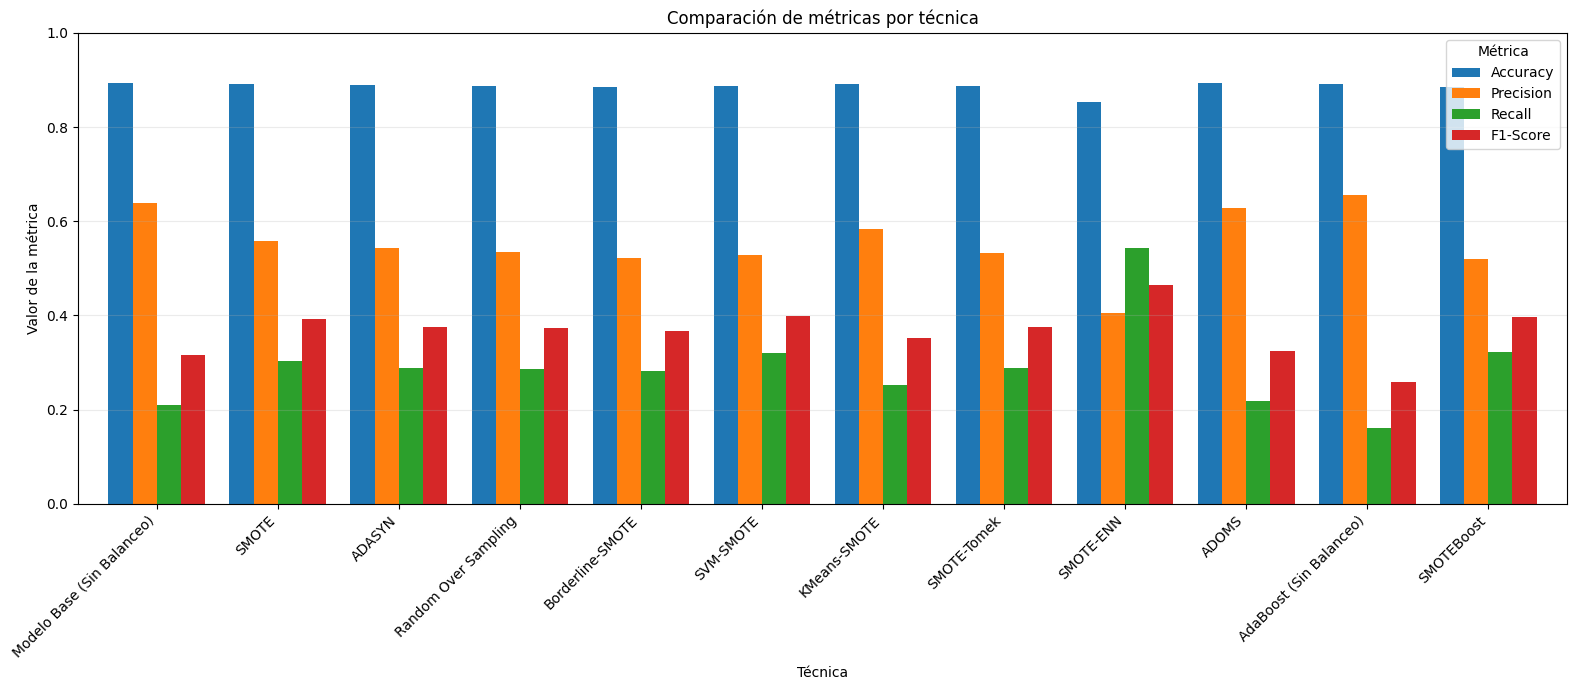


Ranking por Accuracy:


,Accuracy
Técnica,
Modelo Base (Sin Balanceo),0.8937
ADOMS,0.8935
AdaBoost (Sin Balanceo),0.8920
KMeans-SMOTE,0.8914
SMOTE,0.8904
ADASYN,0.8883
Random Over Sampling,0.8873
SMOTE-Tomek,0.8872
SVM-SMOTE,0.8870



Ranking por Precision:


,Precision
Técnica,
AdaBoost (Sin Balanceo),0.6552
Modelo Base (Sin Balanceo),0.6398
ADOMS,0.6287
KMeans-SMOTE,0.5826
SMOTE,0.5585
ADASYN,0.5427
Random Over Sampling,0.5344
SMOTE-Tomek,0.5331
SVM-SMOTE,0.5281



Ranking por Recall:


,Recall
Técnica,
SMOTE-ENN,0.5435
SMOTEBoost,0.3223
SVM-SMOTE,0.3195
SMOTE,0.3025
SMOTE-Tomek,0.2892
ADASYN,0.2883
Random Over Sampling,0.2864
Borderline-SMOTE,0.2826
KMeans-SMOTE,0.2533



Ranking por F1-Score:


,F1-Score
Técnica,
SMOTE-ENN,0.4648
SVM-SMOTE,0.3981
SMOTEBoost,0.3977
SMOTE,0.3924
ADASYN,0.3765
SMOTE-Tomek,0.3750
Random Over Sampling,0.3729
Borderline-SMOTE,0.3669
KMeans-SMOTE,0.3531


In [ ]:
metricas_principales = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

ax = tabla_resultados[metricas_principales].plot(
    kind="bar",
    figsize=(16, 7),
    width=0.8
)

plt.title("Comparación de métricas por técnica")
plt.xlabel("Técnica")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Métrica")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Ranking individual por métrica
for metrica in metricas_principales:
    print(f"\nRanking por {metrica}:")
    display(
        tabla_resultados[[metrica]]
        .sort_values(metrica, ascending=False)
        .round(4)
    )

### Interpretación de Accuracy, Precision, Recall y F1-Score

La comparación de Accuracy, Precision, Recall y F1-Score confirma que el balanceo modifica principalmente la capacidad del modelo para detectar la clase minoritaria. El modelo base de Random Forest obtuvo una Accuracy de **0.8937** y una Precision de **0.6398**, pero solo alcanzó un Recall de **0.2098**. Esto significa que conserva un buen desempeño global, aunque deja sin identificar una parte importante de los casos positivos.

Las técnicas de balanceo aumentaron el Recall en prácticamente todos los experimentos, aunque a cambio de una reducción de Precision. **SMOTE-ENN** produjo el cambio más pronunciado: el Recall pasó de **0.2098 a 0.5435**, un incremento de aproximadamente **33.36 puntos porcentuales**, mientras que el F1-Score aumentó de **0.3160 a 0.4648**. Sin embargo, su Precision disminuyó hasta **0.4061** y su Accuracy hasta **0.8536**, mostrando que la mayor sensibilidad también genera más falsos positivos.

**SVM-SMOTE** presentó un compromiso más moderado. Su Recall aumentó hasta **0.3195** y el F1-Score hasta **0.3981**, mientras que la Accuracy permaneció en **0.8870**. De esta manera, logró mejorar considerablemente la detección de positivos sin producir una reducción tan pronunciada de Accuracy como SMOTE-ENN.

En el extremo más conservador se encuentra **ADOMS**, cuya Accuracy de **0.8935** y Precision de **0.6287** permanecieron muy próximas a las del modelo base. No obstante, el Recall solo aumentó hasta **0.2193**, por lo que la mejora en la detección de la clase minoritaria fue pequeña.

En conjunto, F1-Score permite apreciar mejor este compromiso que Accuracy de forma aislada. Según esta métrica, SMOTE-ENN presentó el mejor equilibrio entre Precision y Recall, mientras que SVM-SMOTE fue la alternativa que logró una mejora relevante manteniendo un comportamiento global más cercano al modelo original.

## 7.3. ROC-AUC

ROC-AUC evalúa la capacidad del modelo para diferenciar entre ambas clases considerando distintos umbrales de clasificación. Se utiliza como complemento de las métricas calculadas con el umbral de decisión predeterminado.

,ROC-AUC
Técnica,
SVM-SMOTE,0.7976
SMOTE-ENN,0.7967
ADOMS,0.7936
KMeans-SMOTE,0.7909
SMOTE-Tomek,0.7909
Random Over Sampling,0.7896
Modelo Base (Sin Balanceo),0.7896
ADASYN,0.7887
SMOTE,0.7881


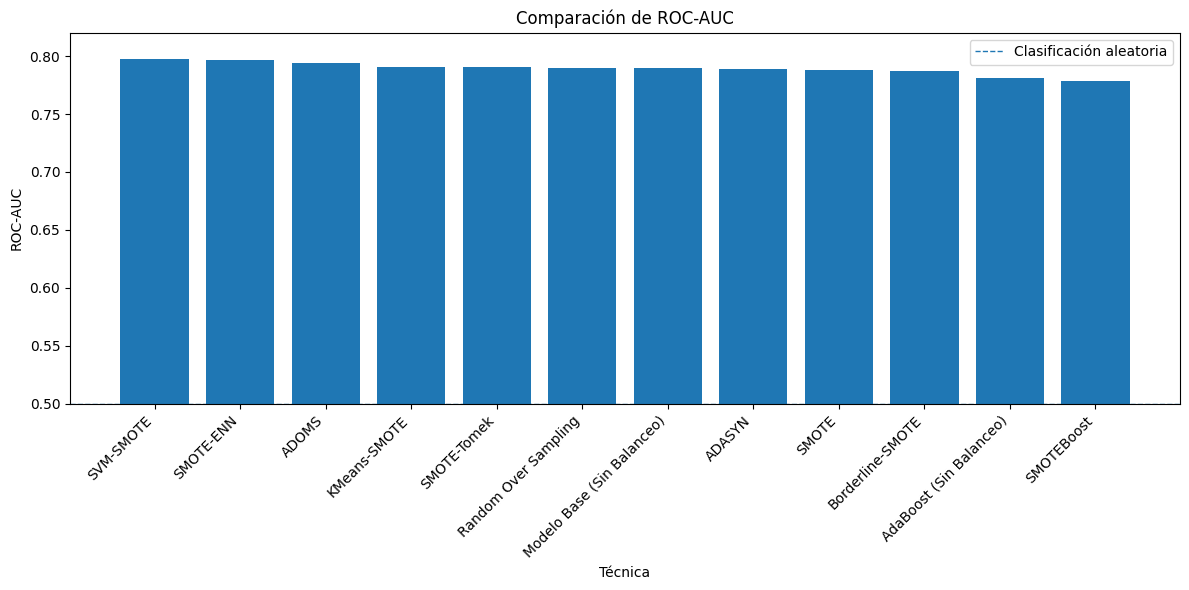

Mayor ROC-AUC: SVM-SMOTE (0.7976)


In [ ]:
roc_ordenado = (
    tabla_resultados[["ROC-AUC"]]
    .sort_values("ROC-AUC", ascending=False)
)

display(roc_ordenado.round(4))

plt.figure(figsize=(12, 6))

plt.bar(
    roc_ordenado.index,
    roc_ordenado["ROC-AUC"]
)

plt.axhline(
    y=0.5,
    linestyle="--",
    linewidth=1,
    label="Clasificación aleatoria"
)

plt.title("Comparación de ROC-AUC")
plt.xlabel("Técnica")
plt.ylabel("ROC-AUC")
plt.ylim(0.5, 0.82)
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

mejor_roc = roc_ordenado.index[0]
valor_mejor_roc = roc_ordenado.iloc[0, 0]

print(
    f"Mayor ROC-AUC: {mejor_roc} "
    f"({valor_mejor_roc:.4f})"
)

### Interpretación de ROC-AUC

Los valores de ROC-AUC muestran diferencias menores que las observadas en Recall y F1-Score. **SVM-SMOTE** alcanzó el mayor resultado con **0.7976**, seguido muy de cerca por **SMOTE-ENN (0.7967)** y **ADOMS (0.7936)**. El modelo base obtuvo **0.7896**.

En términos absolutos, la mejora de SVM-SMOTE respecto al modelo base fue de aproximadamente **0.0081**, mientras que SMOTE-ENN aumentó el ROC-AUC en **0.0071**. Por tanto, aunque ambas técnicas mejoran la capacidad general de discriminación, las diferencias de ROC-AUC son relativamente pequeñas.

Este resultado es importante porque el aumento considerable de Recall observado en algunas técnicas no necesariamente implica un aumento igualmente grande de ROC-AUC. Por ejemplo, SMOTE-ENN consiguió un Recall mucho mayor, pero su ROC-AUC quedó prácticamente al mismo nivel que SVM-SMOTE. Esto se debe a que Recall representa el comportamiento para un umbral de decisión específico, mientras que ROC-AUC evalúa el desempeño del modelo a través de múltiples umbrales.

También se observa que algunas técnicas, como SMOTE y Borderline-SMOTE, aumentaron Recall y F1-Score pero presentaron un ROC-AUC ligeramente inferior al modelo base. Esto indica que su beneficio provino principalmente de modificar el comportamiento de clasificación en el umbral utilizado y no necesariamente de mejorar la capacidad global de separación entre clases.

En consecuencia, **SVM-SMOTE presentó la mejor capacidad global de discriminación**, aunque la diferencia respecto a SMOTE-ENN fue pequeña.

## 7.4. Comparación gráfica

Para evaluar correctamente el efecto del balanceo, se calcula la variación de cada técnica respecto a su modelo de referencia. Las técnicas basadas en Random Forest se comparan con el Random Forest sin balanceo, mientras que SMOTEBoost se compara con AdaBoost sin balanceo.

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Técnica,,,,,
SMOTE,-0.0033,-0.0813,+0.0926,+0.0764,-0.0015
ADASYN,-0.0054,-0.0971,+0.0784,+0.0605,-0.0009
Random Over Sampling,-0.0064,-0.1054,+0.0766,+0.0569,+0.0000
Borderline-SMOTE,-0.0079,-0.1170,+0.0728,+0.0509,-0.0021
SVM-SMOTE,-0.0067,-0.1116,+0.1096,+0.0821,+0.0081
KMeans-SMOTE,-0.0023,-0.0572,+0.0435,+0.0371,+0.0013
SMOTE-Tomek,-0.0065,-0.1067,+0.0794,+0.0590,+0.0013
SMOTE-ENN,-0.0401,-0.2337,+0.3336,+0.1488,+0.0071
ADOMS,-0.0002,-0.0110,+0.0095,+0.0091,+0.0041


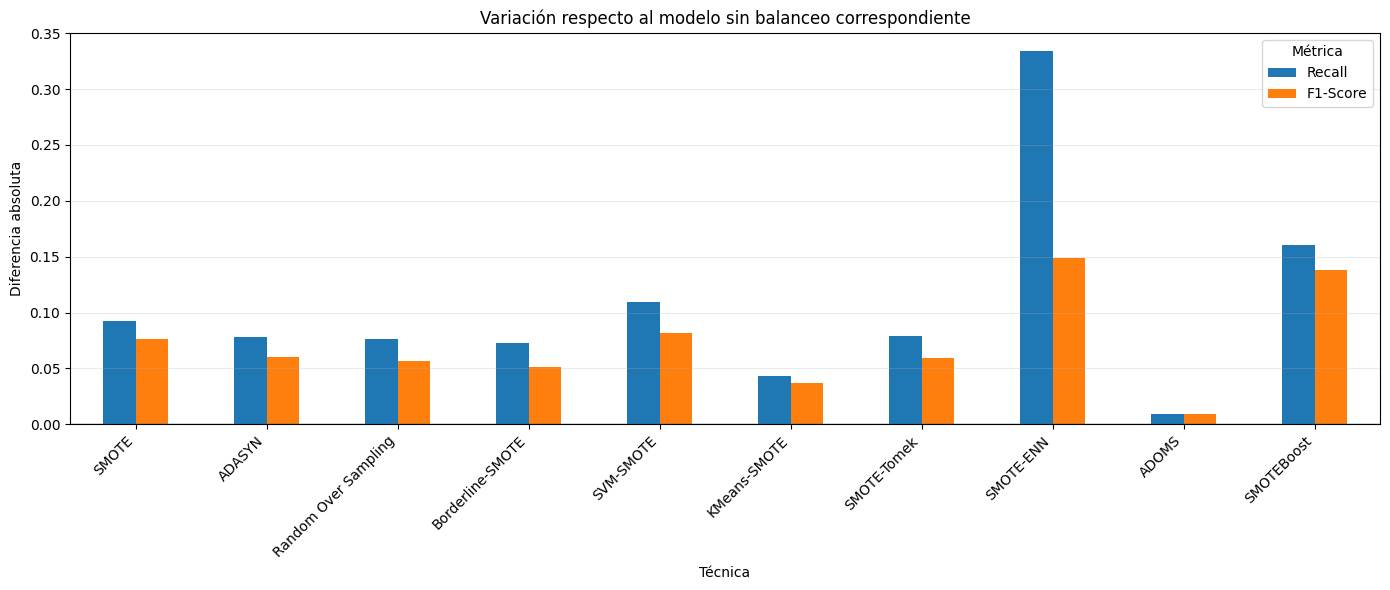

In [ ]:
# Técnicas evaluadas utilizando Random Forest
tecnicas_rf = [
    "SMOTE",
    "ADASYN",
    "Random Over Sampling",
    "Borderline-SMOTE",
    "SVM-SMOTE",
    "KMeans-SMOTE",
    "SMOTE-Tomek",
    "SMOTE-ENN",
    "ADOMS"
]

metricas = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

base_rf = tabla_resultados.loc[
    "Modelo Base (Sin Balanceo)",
    metricas
]

comparacion_base = (
    tabla_resultados.loc[tecnicas_rf, metricas]
    .subtract(base_rf)
)

# SMOTEBoost utiliza otro clasificador, por lo que se compara
# únicamente con AdaBoost sin balanceo.
if (
    "SMOTEBoost" in tabla_resultados.index
    and "AdaBoost (Sin Balanceo)" in tabla_resultados.index
):
    diferencia_smoteboost = (
        tabla_resultados.loc["SMOTEBoost", metricas]
        - tabla_resultados.loc[
            "AdaBoost (Sin Balanceo)",
            metricas
        ]
    )

    comparacion_base.loc["SMOTEBoost"] = diferencia_smoteboost

display(
    comparacion_base
    .round(4)
    .style
    .format("{:+.4f}")
)

# Visualización de los cambios en Recall y F1
ax = comparacion_base[
    ["Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.axhline(0, linewidth=1)
plt.title("Variación respecto al modelo sin balanceo correspondiente")
plt.xlabel("Técnica")
plt.ylabel("Diferencia absoluta")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Métrica")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretación de la variación respecto al modelo base

La comparación mediante diferencias permite observar con mayor claridad cuánto aporta cada técnica respecto a su modelo sin balanceo correspondiente.

Dentro de las técnicas evaluadas con Random Forest, **SMOTE-ENN produjo la mayor mejora en Recall y F1-Score**. El Recall aumentó en **0.3336** y el F1-Score en **0.1488**. Esta mejora estuvo acompañada por las mayores reducciones de Accuracy (**-0.0401**) y Precision (**-0.2337**), por lo que representa la estrategia más agresiva: detecta muchos más positivos, pero también incrementa considerablemente los falsos positivos.

**SVM-SMOTE** mostró un comportamiento más equilibrado. Incrementó el Recall en **0.1096**, el F1-Score en **0.0821** y el ROC-AUC en **0.0081**, mientras que su pérdida de Accuracy fue de solo **0.0067**. Por ello, constituye una alternativa interesante cuando se busca mejorar la detección de la clase minoritaria sin modificar excesivamente el comportamiento global del modelo.

**SMOTE** también generó una mejora relevante, aumentando el Recall en **0.0926** y el F1-Score en **0.0764**, con una pérdida de Accuracy relativamente pequeña de **0.0033**. ADASYN, Random Over Sampling, Borderline-SMOTE y SMOTE-Tomek presentaron el mismo patrón general, aunque con beneficios algo menores.

**KMeans-SMOTE y ADOMS** fueron las alternativas más conservadoras. KMeans-SMOTE redujo la Accuracy únicamente en **0.0023**, mientras que ADOMS prácticamente la mantuvo, con una diferencia de **-0.0002**. Sin embargo, sus aumentos de Recall fueron de solo **0.0435** y **0.0095**, respectivamente.

Para **SMOTEBoost**, la comparación se realiza con AdaBoost sin balanceo y no con Random Forest. En este caso, el Recall aumentó en **0.1607** y el F1-Score en **0.1384**, aunque la Precision disminuyó en **0.1361**. Además, el ROC-AUC se redujo ligeramente en **0.0026**. Esto indica que SMOTEBoost mejoró considerablemente la detección de positivos con el umbral utilizado, pero no aumentó la capacidad general de discriminación de AdaBoost.

## 7.5. Fortalezas y debilidades generales

Los experimentos muestran que ninguna técnica de balanceo mejora simultáneamente todas las métricas. En general, al aumentar la capacidad para detectar la clase positiva se produce una disminución de Precision y, en algunos casos, de Accuracy. Por ello, las fortalezas y debilidades deben interpretarse considerando el objetivo de clasificación y no únicamente el grado de balance alcanzado.

**SMOTE** consiguió una mejora clara de Recall y F1-Score con una pérdida pequeña de Accuracy. Su principal fortaleza fue aumentar la detección de positivos sin modificar drásticamente el rendimiento global. Como debilidad, redujo la Precision y presentó un ROC-AUC ligeramente inferior al modelo base.

**ADASYN** también aumentó Recall y F1-Score, aunque su mejora fue menor que la obtenida mediante SMOTE y SVM-SMOTE. Además, disminuyó más la Precision, por lo que no presentó una ventaja clara sobre SMOTE en este conjunto de datos.

**Random Over Sampling** ofreció una mejora moderada en Recall y F1-Score y mantuvo exactamente el mismo ROC-AUC que el modelo base. Su principal ventaja es que consigue mejorar la sensibilidad sin generar observaciones mediante interpolación. Sin embargo, la reducción de Precision indica que la duplicación de observaciones minoritarias también incrementó los falsos positivos.

**Borderline-SMOTE** aumentó Recall y F1-Score, pero presentó la menor Accuracy entre varias de las variantes de SMOTE y un ROC-AUC de **0.7874**, inferior al modelo base. En este dataset no mostró una ventaja clara frente a otras variantes.

**SVM-SMOTE** fue una de las técnicas más equilibradas. Obtuvo el mayor ROC-AUC (**0.7976**), mejoró el Recall hasta **0.3195** y alcanzó un F1-Score de **0.3981**, manteniendo una Accuracy de **0.8870**. Su principal debilidad fue la reducción de Precision respecto al modelo base, aunque el sacrificio fue menor que el producido por SMOTE-ENN en términos globales.

**KMeans-SMOTE** conservó relativamente bien Accuracy y Precision, pero produjo mejoras limitadas en Recall y F1-Score. Puede considerarse una alternativa conservadora, aunque no consiguió explotar el balanceo tanto como otras técnicas.

**SMOTE-Tomek** presentó mejoras moderadas en Recall, F1-Score y ROC-AUC. El proceso de generación y posterior limpieza de muestras permitió mantener un comportamiento estable, pero sus resultados no superaron a SVM-SMOTE ni a SMOTE-ENN en las métricas principales.

**SMOTE-ENN** fue la técnica con mayor impacto sobre la clase minoritaria. Alcanzó el mayor Recall (**0.5435**) y F1-Score (**0.4648**), lo que representa una mejora sustancial respecto al modelo base. Su principal debilidad fue la fuerte reducción de Precision hasta **0.4061** y de Accuracy hasta **0.8536**. Por tanto, resulta especialmente conveniente cuando el costo de no detectar un caso positivo es mayor que el costo de generar falsos positivos.

**ADOMS** fue la alternativa más conservadora. Mantuvo una Accuracy de **0.8935** y una Precision de **0.6287**, prácticamente equivalentes al modelo base, y mejoró el ROC-AUC hasta **0.7936**. Sin embargo, el Recall solo aumentó de **0.2098 a 0.2193**, por lo que su efecto sobre el problema de desbalance fue limitado.

**SMOTEBoost**, comparado específicamente con AdaBoost sin balanceo, aumentó considerablemente Recall y F1-Score. El Recall pasó de **0.1616 a 0.3223** y el F1-Score de **0.2593 a 0.3977**. Su debilidad fue la caída de Precision y una pequeña reducción de ROC-AUC. Debido a que utiliza AdaBoost como clasificador, sus resultados no deben compararse de manera completamente directa con los métodos evaluados mediante Random Forest.

En términos generales, los resultados permiten identificar tres comportamientos. **SMOTE-ENN prioriza la detección de la clase positiva**, aceptando una mayor cantidad de falsos positivos; **SVM-SMOTE ofrece el mejor compromiso entre discriminación, Recall y rendimiento global**; y **ADOMS prioriza la conservación de Accuracy y Precision, pero mejora muy poco la detección de la clase minoritaria**. La selección final debe realizarse considerando cuál de estos objetivos es más importante para el problema analizado.

# 8. Selección de la mejor técnica

## 8.1. Análisis de resultados

La selección de la mejor técnica se realiza considerando principalmente **Recall** y **F1-Score**, debido a que el dataset presenta desbalance de clases y el objetivo es mejorar la identificación de la clase positiva (`yes`). La Accuracy se utiliza como métrica complementaria, ya que puede resultar elevada aun cuando se detecten pocos casos de la clase minoritaria.

Entre las técnicas evaluadas, los resultados más relevantes fueron:

| Técnica | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| **SMOTE-ENN** | 0.8536 | 0.4061 | **0.5435** | **0.4648** | 0.7967 |
| **SVM-SMOTE** | 0.8870 | 0.5281 | 0.3195 | 0.3981 | **0.7976** |
| **SMOTE** | 0.8904 | 0.5585 | 0.3025 | 0.3924 | 0.7881 |
| Modelo base | **0.8937** | **0.6398** | 0.2098 | 0.3160 | 0.7896 |

**SMOTE-ENN** presentó la mayor mejora en la detección de la clase positiva: elevó el Recall de **0.2098 a 0.5435** y el F1-Score de **0.3160 a 0.4648**. Aunque disminuyó Accuracy y Precision, logró el mejor desempeño en las métricas más importantes para tratar el desbalance.


## 8.2. Técnica seleccionada
La técnica seleccionada como mejor alternativa es **SMOTE-ENN**.

Esta combinación aplica primero **SMOTE** para generar ejemplos sintéticos de la clase minoritaria y posteriormente **Edited Nearest Neighbours (ENN)** para eliminar observaciones ambiguas o ruidosas. En el conjunto de entrenamiento resultante se obtuvieron **30 383 registros de la clase positiva y 21 771 de la clase negativa**.

## 8.3. Justificación

Se seleccionó **SMOTE-ENN** porque obtuvo el **mayor Recall (0.5435)** y el **mayor F1-Score (0.4648)** de todas las técnicas evaluadas. Esto significa que fue la alternativa que logró identificar una mayor proporción de clientes de la clase positiva y, al mismo tiempo, presentó el mejor equilibrio entre Precision y Recall para dicha clase.

Respecto al modelo base, el Recall aumentó en **0.3336** y el F1-Score en **0.1488**. Como costo de esta mejora, la Accuracy disminuyó de **0.8937 a 0.8536** y la Precision de **0.6398 a 0.4061**, debido al incremento de falsos positivos. Sin embargo, para un problema con clases desbalanceadas se considera más importante recuperar una mayor cantidad de casos positivos que maximizar únicamente la Accuracy global.

Por estas razones, **SMOTE-ENN ofrece el mejor resultado para el objetivo de balanceo**, mientras que SVM-SMOTE queda como una alternativa más conservadora cuando se desea preservar una Accuracy mayor.

# 9. Dataset final preparado

## 9.1. Dimensiones finales

In [ ]:
# 9.1 Dimensiones finales tras aplicar SMOTE-ENN
print("--- DIMENSIONES FINALES DEL CONJUNTO DE ENTRENAMIENTO ---")
print(f"Dimensiones de variables predictoras (X_train_senn): {X_train_senn.shape[0]} filas y {X_train_senn.shape[1]} columnas")
print(f"Dimensiones de la variable objetivo (y_train_senn): {y_train_senn.shape[0]} filas")

# Verificación de que no existan valores nulos residuales
nulos_restantes = X_train_senn.isna().sum().sum()
print(f"Cantidad total de valores nulos en el dataset final: {nulos_restantes}")

--- DIMENSIONES FINALES DEL CONJUNTO DE ENTRENAMIENTO ---
Dimensiones de variables predictoras (X_train_senn): 52154 filas y 34 columnas
Dimensiones de la variable objetivo (y_train_senn): 52154 filas
Cantidad total de valores nulos en el dataset final: 0


El resultado de esta sección confirma que el conjunto de datos de entrenamiento ha incrementado su volumen debido a la técnica de sobremuestreo, alcanzando un total de 52,154 registros (sumando ambas clases). Además, la auditoría final garantiza la calidad e integridad de los datos al verificar que no existe ningún valor nulo residual en la matriz, dejándola estructurada y libre de errores para el entrenamiento.

## 9.2. Variables finales

In [ ]:
# 9.2 Variables finales
print("--- VARIABLES PREDICTORAS FINALES ---")
columnas_finales = X_train_senn.columns.tolist()
print(f"Lista de características ({len(columnas_finales)} en total):")
print(columnas_finales)

print("\nVista previa de los datos de entrenamiento listos para el modelo:")
display(X_train_senn.head())

--- VARIABLES PREDICTORAS FINALES ---
Lista de características (34 en total):
['age', 'default', 'housing', 'loan', 'balance_log', 'campaign_log', 'previous_log', 'contactado_antes', 'pdays_log', 'mes_sin', 'mes_cos', 'dia_sin', 'dia_cos', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown', 'marital_married', 'marital_single', 'education_secondary', 'education_tertiary', 'education_unknown', 'contact_telephone', 'contact_unknown', 'poutcome_other', 'poutcome_success', 'poutcome_unknown']

Vista previa de los datos de entrenamiento listos para el modelo:


,age,default,housing,loan,balance_log,campaign_log,previous_log,contactado_antes,pdays_log,mes_sin,...,marital_married,marital_single,education_secondary,education_tertiary,education_unknown,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown
0,-0.460434,0.0,0.0,0.0,0.490310,-0.117143,-0.423167,0.0,-0.466498,-1.446393,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.668773,0.0,0.0,0.0,-1.287898,2.592311,-0.423167,0.0,-0.466498,-0.849048,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,0.668773,0.0,0.0,1.0,0.638489,-0.909607,-0.423167,0.0,-0.466498,-0.849048,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.856974,0.0,1.0,0.0,0.914083,2.592311,-0.423167,0.0,-0.466498,-0.849048,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.480572,0.0,0.0,1.0,-3.040146,-0.909607,-0.423167,0.0,-0.466498,1.380273,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


Se demuestra el éxito de las fases de codificación y Feature Engineering, listando el conjunto definitivo de características predictoras. Se evidencia que todas las variables son ahora puramente numéricas e incluyen tanto las codificaciones binarias (One-Hot Encoding) como las nuevas transformaciones matemáticas avanzadas (logaritmos y variables cíclicas espaciales), reemplazando definitivamente a las columnas originales que no eran aptas para el modelo.

## 9.3. Distribución final de clases

--- DISTRIBUCIÓN FINAL DE LA VARIABLE OBJETIVO (TRAIN) ---


,frecuencia,porcentaje (%)
0 (no),30383,58.26
1 (yes),21771,41.74


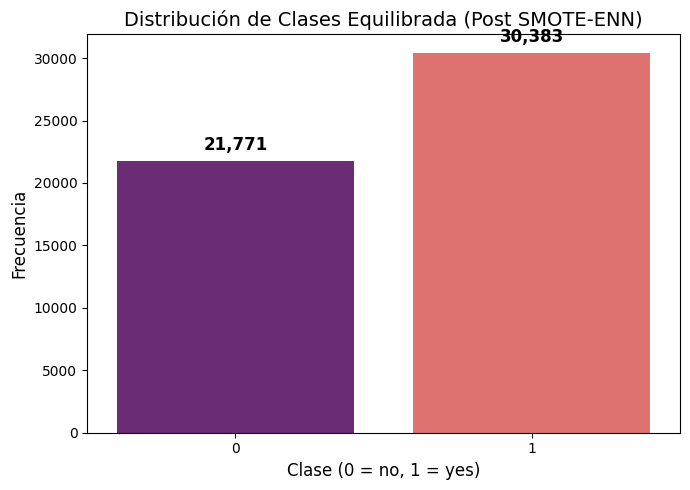

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 9.3 Distribución final de clases (Set de Entrenamiento)
distribucion_y_final = pd.DataFrame({
    'frecuencia': y_train_senn.value_counts(),
    'porcentaje (%)': (y_train_senn.value_counts(normalize=True) * 100).round(2)
})

# Renombramos el índice si las clases son numéricas 0 y 1
if 0 in distribucion_y_final.index:
    distribucion_y_final.index = ['0 (no)', '1 (yes)']

print("--- DISTRIBUCIÓN FINAL DE LA VARIABLE OBJETIVO (TRAIN) ---")
display(distribucion_y_final)

# Visualización gráfica de la nueva distribución balanceada
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=y_train_senn, palette="magma")
plt.title("Distribución de Clases Equilibrada (Post SMOTE-ENN)", fontsize=14)
plt.xlabel("Clase (0 = no, 1 = yes)", fontsize=12)
plt.ylabel("Frecuencia", fontsize=12)

# Añadir las etiquetas exactas de cantidad
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',
                fontsize=12, color='black', xytext=(0, 5),
                textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

El gráfico y la tabla evidencian visual y numéricamente la corrección exitosa del desbalance original. Gracias a la aplicación de SMOTE-ENN, la clase positiva ("yes") cuenta ahora con 30,383 ejemplos y la clase negativa ("no") con 21,771. Esta nueva distribución proporciona al modelo predictivo una base de aprendizaje equitativa, asegurando que el algoritmo penalice correctamente los errores y aprenda a identificar de manera óptima a los clientes que sí suscriben el depósito.

# 10. Conclusiones

## 10.1. Limpieza y calidad de los datos

El dataset original estuvo compuesto por **45 211 registros y 17 variables**. Durante la etapa de limpieza no se encontraron valores nulos reales, cadenas vacías, registros duplicados ni valores imposibles, por lo que no fue necesario eliminar observaciones. Se identificaron categorías `unknown` en variables como `poutcome`, `contact`, `education` y `job`, pero se conservaron al representar información existente en el conjunto original.

También se detectaron valores atípicos mediante el método IQR, principalmente en `balance`, `duration`, `campaign` y `age`. Estos valores no fueron eliminados porque podían corresponder a comportamientos válidos de los clientes. Como resultado, el proceso de limpieza conservó los **45 211 registros originales**, manteniendo la integridad de la información.

## 10.2. Transformación y Feature Engineering

Las variables categóricas fueron transformadas a una representación numérica y las variables continuas fueron evaluadas mediante normalización y estandarización. Para las etapas posteriores se seleccionó la **estandarización**, debido a que permite trabajar con variables numéricas en una escala comparable.

En la etapa de Feature Engineering se aplicaron transformaciones logarítmicas a variables con distribuciones asimétricas, se creó la característica `contactado_antes` y se representaron variables temporales como mes y día mediante componentes seno y coseno. Asimismo, se eliminaron las variables originales reemplazadas por estas transformaciones, incluyendo `balance`, `campaign`, `previous`, `pdays`, `month`, `day` y `duration`.

Después de la codificación y del Feature Engineering se obtuvo un conjunto de **34 variables predictoras**, todas numéricas, manteniendo los **45 211 registros** del dataset original.

## 10.3. Efecto del desbalance sobre el modelo base

La variable objetivo presentó inicialmente un desbalance considerable: **88.3 % de los registros correspondían a la clase `no` y 11.7 % a la clase `yes`**. Esta distribución también se conservó en los conjuntos de entrenamiento y prueba debido al uso de una división estratificada.

El modelo base sin balanceo alcanzó una **Accuracy de 0.8937** y una **Precision de 0.6398**, pero obtuvo un **Recall de solo 0.2098** y un **F1-Score de 0.3160** para la clase positiva. Esto demuestra que una Accuracy elevada no era suficiente para evaluar el problema, ya que el modelo identificaba correctamente solo una pequeña proporción de los clientes que sí pertenecían a la clase positiva.

## 10.4. Comparación de las técnicas de balanceo

Las técnicas de balanceo produjeron distintos compromisos entre Accuracy, Precision y capacidad para detectar la clase minoritaria. En términos generales, el incremento de Recall estuvo acompañado por una disminución de Precision, debido a que los modelos comenzaron a clasificar una mayor cantidad de observaciones como positivas.

**SMOTE-ENN** produjo la mayor mejora en la detección de la clase positiva, alcanzando un **Recall de 0.5435** y un **F1-Score de 0.4648**, los valores más altos entre las técnicas evaluadas. Frente al modelo base, esto representa incrementos de **0.3336 en Recall** y **0.1488 en F1-Score**. Como contrapartida, la Accuracy disminuyó a **0.8536** y la Precision a **0.4061**.

Por otro lado, **SVM-SMOTE** obtuvo el mayor **ROC-AUC, con 0.7976**, y presentó un comportamiento más conservador, con una Accuracy de **0.8870**, Recall de **0.3195** y F1-Score de **0.3981**. Esto indica que SVM-SMOTE presentó la mejor capacidad global de discriminación, mientras que SMOTE-ENN priorizó con mayor intensidad la recuperación de casos positivos.

## 10.5. Técnica seleccionada y dataset final

Para este laboratorio se seleccionó **SMOTE-ENN** debido a que el objetivo principal frente al desbalance era mejorar la identificación de la clase minoritaria. Su mayor Recall y F1-Score indican que fue la técnica que permitió recuperar una mayor proporción de clientes de la clase `yes`, aunque a costa de incrementar los falsos positivos.

Después de aplicar SMOTE-ENN al conjunto de entrenamiento se obtuvieron **52 154 registros y 34 variables predictoras**, sin valores nulos. La distribución final quedó formada por **30 383 observaciones de la clase `no` (58.26 %) y 21 771 de la clase `yes` (41.74 %)**.

Por lo tanto, SMOTE-ENN no generó una distribución exactamente 50/50, pero redujo sustancialmente el desbalance original de 88.3/11.7 y proporcionó un conjunto de entrenamiento considerablemente más equilibrado.

## 10.6. Conclusión general

El laboratorio permitió comprobar que la preparación de datos no se limita a limpiar registros, sino que también incluye transformar variables, construir nuevas características y adecuar la distribución de las clases al problema de aprendizaje automático.

En este dataset, la principal dificultad no estuvo relacionada con valores faltantes o registros inválidos, sino con el fuerte desbalance de la variable objetivo. El modelo sin balanceo presentó una Accuracy elevada, pero una baja capacidad para identificar clientes de la clase positiva. La aplicación de técnicas de sobremuestreo y métodos híbridos permitió mejorar esta situación en diferentes grados.

Entre las técnicas evaluadas, **SMOTE-ENN fue la alternativa más efectiva para aumentar Recall y F1-Score**, mientras que **SVM-SMOTE obtuvo el mejor ROC-AUC y un comportamiento más equilibrado**. Esto demuestra que no existe una técnica de balanceo universalmente superior: la selección depende de la métrica que se considere más importante para el problema.

Finalmente, el dataset quedó limpio, completamente numérico, transformado mediante Feature Engineering y con una distribución de clases mucho más equilibrada, por lo que se encuentra preparado para posteriores etapas de modelado y evaluación.